# Predicting poverty and wealth from mobile phone metadata 可审计复刻

## 1. 研究问题、阅读目标与复刻边界

### 1.1 这篇研究究竟想解决什么问题？

发展中国家的政府和研究机构通常需要知道“贫困人口在哪里、不同地区的生活水平如何”，但人口普查和住户调查价格高、周期长，且很难频繁更新。Blumenstock、Cadamuro 与 On（2015）提出的核心问题是：**能否先用少量电话调查得到真实的社会经济标签，再从大量、被动产生的手机通信元数据中学习标签与行为之间的关系，从而推断全国手机用户的财富状况和空间分布？**

这项研究不是在证明“某种打电话方式导致富裕”，也不是要用手机记录取代所有官方统计。它完成的是一个**监督学习与小区域估计问题**：在一小批同时拥有调查回答和通话详单的用户上训练预测模型，再把模型外推到更大的手机用户总体，最后用独立的政府 DHS 调查检验空间汇总结果是否可信。

### 1.2 论文的三层证据链

1. **个体层预测**：对 856 名电话调查受访者，用其历史 CDR 特征预测财富指数、资产拥有情况和相对贫困身份；正文 Figure 1 与 Table S1 回答“数字足迹对同一个人的调查回答有多大预测力”。
2. **全国空间外推**：把已训练模型应用于约 150 万名运营商用户，并利用基站位置推断用户的大致居住地；正文 Figure 2 展示“从个体预测汇总成高分辨率财富地图”的可能性。
3. **独立外部验证**：把手机模型的地区或 DHS 聚类汇总值，与没有参与模型训练的 2007/2010 DHS 统计量比较；正文 Figure 3 及补充图检验模型是否只是在小样本中拟合得好，还是能恢复真实的空间差异。

这三层不能相互替代。交叉验证解决的是训练样本内部的泛化问题；DHS 外部验证解决的是换数据来源、换人群和换空间尺度后的可信度问题；全国精细地图则仍受到“没有同等分辨率真值”的限制。

### 1.3 本 Notebook 的学习目标

运行并阅读本 Notebook 后，读者应能够：

- 说清楚电话调查、CDR、DHS、行政区边界和夜间灯光在研究中分别扮演什么角色；
- 理解 PCA 财富指数、DFA 特征工程、弹性网、五折交叉验证、ROC/AUC、加权相关和 Voronoi 空间匹配的直观含义；
- 区分“重新训练模型”“使用论文保存的中间结果重算指标”和“只按论文方法画教学示意”三种完全不同的复刻强度；
- 看懂每段 Python 代码读入什么、做了什么检查、输出应如何解释，以及为什么某些图在公开数据条件下不能诚实复刻。

### 1.4 数据使用与科研诚信边界

本 Notebook 只使用 ICPSR 100144-V5.1 归档中实际可读的原研究文件。原始运营商 CDR、全国 150 万用户的完整预测与位置、完整 DHS 微观数据和原始塔址并未公开，因此不会用模拟数据、其他国家数据、现代手机数据或替代性贫困指标填补。唯一外部文件是世界银行公开的 2012 年卢旺达区级行政边界；它只提供客观几何轮廓，不含任何财富、贫困或用电变量。

### 1.5 本 Notebook 使用的复刻等级

- **严格复刻**：由归档中同一数值输入重新计算指标或重画图形。
- **基于原始中间结果重绘**：归档保留了模型预测、ROC 点或地区汇总输出；本 Notebook 对这些原研究中间结果重新作图或复算，但不声称从原始 CDR 重新估计模型。
- **方法教学示意**：根据论文方法画出流程或概念图，帮助理解，但它不是原图中的实证数值结果。
- **无法复刻**：关键输入没有公开，或归档只保留表头/一行示例；明确报告缺口，不生成看似完整的替代图。

> **重要提醒**：Table 1 是四类数据集的描述性样本概况，而不是模型估计结果；依照本次任务要求不复刻。Table S1 才是需要讨论的模型性能结果表。


### 1.6 阅读导航：把论文叙事与代码执行对应起来

Notebook 按照“先理解研究，再检查数据，随后复刻结果，最后解释局限”的顺序组织：

1. **第 2 节：原研究设计**——介绍样本如何得到、财富标签如何构造、手机行为如何变成特征、模型如何训练以及空间验证如何完成。
2. **第 3 节：公开归档审计**——先看文件是否真的包含足够行数，再决定哪些结果可以复刻。对复刻研究而言，这一步与建模同样重要。
3. **第 4 节：正文 Figure 1–3**——从个体预测到全国地图，再到独立 DHS 验证，沿着论文的主证据链阅读。
4. **第 5 节：Supplementary Figure S1–S8**——解释特征工程、样本量、特征类别、正则化、空间匹配、城乡异质性、夜间灯光和跨期插补。
5. **第 6–8 节：Table S1、总体结论和来源**——区分可重新计算的性能指标与只能引用的论文报告值，并总结研究能说明什么、不能说明什么。

#### 初学者如何阅读代码单元

- 以 `#` 开头的行是中文注释，只负责解释，不会被 Python 当作分析命令执行。
- `pd.read_csv(...)` 表示把表格读入内存；`DataFrame` 可以理解为带列名的电子表格。
- `assert 条件, 提示` 是主动质量检查：若条件不成立，程序会立刻停止，避免带着错误数据继续画图。
- `display(...)` 用于展示表格；`print(...)` 用于输出关键数字；`plt.subplots(...)` 创建画布和坐标轴。
- 建议按从上到下的顺序运行。后面的单元会使用前面已经创建的路径、函数和数据对象。

> **图形格式约定**：所有 Matplotlib 图在 Notebook 输出区以内嵌 SVG 显示，可无损缩放；代码不会把图像写入原始数据目录，也不会改写 ICPSR 文件。


## 2. 原文研究设计：从少量调查标签到全国财富地图

### 2.1 第一步：抽取并调查一小批有代表性的活跃手机用户

研究对象不是“全体卢旺达人”，而是卢旺达当时最大运营商的**活跃用户**。运营商约有 150 万张登记 SIM，但登记 SIM 不等于真实活跃人数。研究者先保留在 2008 年 10–12 月每个月至少使用过一次的号码，得到约 80 万个活跃号码；再依据多数通话发生地把号码分配到行政区，并按各区活跃用户分布进行地理分层抽样。

2009 年夏季，Kigali Institute of Science and Technology 的调查员对约 900 名用户拨打电话，最多在不同日期和时段尝试三次。最终分析样本为 856 人。联系率约 61%，接通者的合作率约 97%；每位受访者获得 500 卢旺达法郎（约 1 美元），访谈约 10–20 分钟。调查不收集姓名和住址等直接身份信息，并在获得口头知情同意后，才把问卷回答与匿名 CDR 标识连接。

这里有两个代表性层次必须区分：调查样本力求代表“活跃手机用户”，但活跃手机用户通常比全体人口更富裕、受教育程度更高且男性比例更大。因此，个体模型首先只能自然推广到手机用户；能否代表全体人口必须依靠后续 DHS 外部验证，而不能靠假设。

### 2.2 第二步：把多道资产题压缩为一个财富指数

在低收入环境中，收入和消费很难通过一两个电话问题准确测量。论文采用 DHS 常见做法，把住房条件、耐用品拥有情况、家庭人数和儿童数等多个回答标准化后，用**加权主成分分析（weighted PCA）**提取第一主成分，作为潜在长期财富或生活水平的代理指标。

电话问卷很短，不能包含 DHS 的约 70 道资产与住房题。研究者先在 DHS 中选择与完整 DHS 财富第一主成分相关度较高、又适合电话询问的问题。PCA 的权重依据分层抽样权重估计；第一主成分解释约 26% 的资产与家庭特征变异。外部验证时，研究者把电话调查得到的同一组基向量投影到 DHS 的对应问题上，使电话样本和 DHS 财富指标尽可能处在同一尺度。这个步骤定义了模型要预测的连续结果 `wealthActual`。

### 2.3 第三步：从原始 CDR 自动生成 5,088 个候选行为特征

CDR 是通信元数据而非通话内容。原研究获得 2005 年初至 2009 年中的国内/国际通话和短信日志，每条交易大致包含日期时间、匿名主叫与被叫标识、通话时长以及路由基站。研究者不依赖少数手工猜测的指标，而是用确定性有限自动机（DFA）系统组合几类操作：

- **筛选 Filter**：如只保留短信、国际通话、呼入/呼出、超过 60 秒的通话或工作日白天事件；
- **分组 Group By**：按本人（ego）、联系人（alter）或周等时间单位分组；
- **选择 Select**：提取时长、星期、小时或地理坐标等字段；
- **聚合 Aggregate**：计算均值、极值、标准差、总和、唯一值个数、回转半径或熵；
- **网络与时间再聚合**：计算一阶联系人特征的加权平均、周际趋势等；另加入对数和二次变换。

这样得到 5,088 个高度相关的候选特征，覆盖本人/联系人短信活动、通话活动、国际通信、移动模式、局部网络结构和全局网络结构。DFA 的价值不是让每个特征都容易解释，而是用一套受约束的“语法”批量生成特征，减少研究者逐一挑选特征的自由度。

论文同时设置两个基准：一是五个直观特征（总通话量、总短信量、国际通话量、联系人数量/度中心性、回转半径），交叉验证 R² 约 0.20；二是 5,088 个 DFA 特征中单独预测力最强的一个，其含义是“联系人外发短信按星期分布熵的互动频率加权平均”，交叉验证 R² 约 0.38–0.39。这一反直觉的最佳单特征也提醒我们：预测相关性不应被轻率解释为因果机制。

### 2.4 第四步：弹性网选择特征，并用五折交叉验证评估

样本只有 856 人而候选特征有 5,088 个，直接回归极易过拟合。论文使用弹性网，把 L1 的变量选择与 L2 的系数收缩结合起来。正则化强度 λ 越大，模型越简单；λ 过大时遗漏有效信息，过小时训练表现继续上升但测试表现下降。研究者在五折交叉验证中选择使留出数据平均 R² 最好的参数，并用调查权重进行加权 bootstrap 分折，以改善对活跃用户总体的代表性。

最优财富模型保留 101 个特征。正文报告 out-of-fold 的实际财富与预测财富相关系数约为 0.68、R² 约为 0.46。资产拥有与贫困分类则使用相同的“特征工程 + 正则化监督学习”思路，但每个结果变量都会重新选择特征和参数，不能把财富模型的系数直接套用于冰箱、摩托车或用电预测。

### 2.5 第五步：从 856 人外推到约 150 万用户并定位

训练结束后，论文把模型应用到其余运营商用户。每名用户的主要居住位置以**夜间众数基站**近似：先找每小时最常用基站，再找每晚 20:00–次日 06:00 最常出现的小时众数基站，最后跨晚取众数。Figure 2 的精细展示还使用用户所有观测位置的加权重心，并限制在夜间众数基站周围 10 公里，以减小短期旅行对“家”的干扰。

为保护隐私，最精细地图不是逐个显示用户，而是用 k-means 把重心相近的用户分成每组约 5–15 人。地区估计则先在基站 Voronoi 单元内平均用户预测，再按每个基站 Voronoi 单元与行政区相交面积的比例加权汇总。这个空间步骤说明：Figure 2/3 不只是普通散点图，它们依赖完整用户位置、基站坐标和几何叠加。

### 2.6 第六步：用独立 DHS 与夜间灯光验证

研究使用 2007–08 DHS（7,377 户、247 个聚类）和 2010 DHS（12,792 户、492 个聚类）。DHS 家庭具有抽样权重，可构造全国代表性的地区均值。聚类坐标为保护隐私会被随机扰动：城市最多约 2 公里、农村通常最多约 5 公里，另有 1% 农村聚类最多约 10 公里。因此论文把 30 个行政区的结果作为主要证据，把聚类层结果视为更高噪声的补充。

主要外部验证结果是：手机预测的地区财富与 2010 DHS 手机拥有家庭的地区财富相关约 0.917，与全部 DHS 家庭相关约 0.916；聚类层财富相关约 0.79，进一步分为 Kigali 城市聚类约 0.64、其他农村聚类约 0.50；地区用电率相关约 0.93。Kigali 约 0.55 平方公里网格中，手机预测用电与 VIIRS 夜间灯光的相关约 0.58。高相关说明模型捕捉了空间排序，但并不等于每名非手机用户的财富都被准确预测。

### 2.7 论文贡献、应用想象与限制

论文的贡献是把“少量主动调查 + 大量被动数字记录 + 独立官方验证”串成一套低成本测量框架。作者报告电话调查约花费 12,000 美元、四周完成，而典型全国住户调查可能超过 100 万美元并耗时 12–18 个月。补充图 S8 还表明，2009 手机估计与 2010 DHS 的地区相关约 0.91，高于 2007 与 2010 两轮 DHS 的约 0.84，因此数字记录可能用作两次传统调查之间的临时统计。

但方法高度依赖情境：手机拥有和运营商选择可能造成覆盖偏差；不同国家的计费制度、预付费习惯和市场结构会改变行为—财富映射；模型会随技术和行为变化而漂移；原始通信元数据具有显著隐私与商业敏感性。论文因此强调外部验证、定期重新调查与模型校准，而不是把 2009 年卢旺达模型视为可永久、跨国直接使用的通用财富公式。

### 2.8 本次复刻的策略

公开归档保留了哈希后的调查特征、out-of-fold 预测、ROC 曲线点、若干单特征/样本量实验输出和地区/聚类汇总结果，但原始 CDR、全国预测、真实塔址与完整 DHS 被删减或遮蔽。因此本 Notebook 的原则是：**能从原研究中间结果重新计算的就重新计算；只能重画的明确称为重绘；缺少关键输入的就停止并解释原因。**


In [1]:
# 统一路径、依赖、图形风格与小工具函数。
# 请从项目根目录启动 Notebook；所有数据路径都以该目录为起点。
# 这一单元只做准备工作，不读取研究数据，也不拟合模型。
# Path 用来安全拼接跨平台文件路径；warnings 用于控制字体告警。
# NumPy 负责数组与线性代数，pandas 负责表格，Matplotlib 负责作图。
# shapefile（pyshp）只读取卢旺达行政区几何，不提供社会经济数据。
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors, patches, font_manager
from matplotlib_inline.backend_inline import set_matplotlib_formats
import shapefile

# 把当前工作目录解析为绝对路径，后续所有相对路径都从这里出发。
# ARCHIVE 指向只读的 ICPSR 归档；BOUNDARY 指向客观区级边界。
# 95% 正态近似使用 1.96，这是后续 LOESS/加权回归置信线的统一常数。
PROJECT = Path.cwd().resolve()
ARCHIVE = PROJECT / "ICPSR_100144-V5.1"
BOUNDARY = PROJECT / "external_data" / "rwa_district" / "District.shp"
CONFIDENCE_Z = 1.96  # 双侧 95% 正态近似置信区间临界值。

# 在 Notebook 中直接显示可缩放的 SVG；保留文字元素，方便导出后编辑。
# SVG 是矢量格式，放大后线条和文字不会像位图一样变模糊。
# rcParams 统一全篇画图风格；关闭上/右边框只是视觉设置，不改变统计量。
set_matplotlib_formats("svg")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "svg.fonttype": "none",
})

# 自动选择可用中文字体。若环境没有中文字体，隐藏重复警告但不影响计算。
# 中文字体在不同电脑上的名称不同，因此先列出本机可用字体再按优先级选择。
# 若找不到候选字体，只隐藏重复的缺字警告；任何数值计算仍照常完成。
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
font_candidates = ["Microsoft YaHei", "SimHei", "Noto Sans CJK SC", "Microsoft JhengHei", "Arial Unicode MS"]
chinese_font = next((name for name in font_candidates if name in available_fonts), None)
if chinese_font:
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
else:
    warnings.filterwarnings("ignore", message=r"Glyph .* missing from font.*", category=UserWarning)

# 与归档 R 脚本一致的颜色名称：darkBlue/darkRed/brown/blue/orange/darkGreen。
# 下面集中保存论文/归档 R 脚本使用的颜色，避免各图散落硬编码色值。
# 颜色只影响视觉对应关系，不会进入任何相关、回归或 AUC 计算。
PAPER_COLORS = {
    "point_indigo": "#000099",       # R: rgb(0, 0, 153, ...)
    "fit_red": "#8B0000",            # R: darkRed
    "electricity_red": "#A52A2A",    # R: brown
    "motorcycle_blue": "#0000FF",    # R: blue
    "television_orange": "#FFA500",  # R: orange
    "refrigerator_green": "#006400", # R: darkGreen
    "poor_5_magenta": "#CC0066",
    "poor_25_maroon": "#660000",
    "neutral_gray": "#BEBEBE",       # R: grey
}
PAPER_ROC_COLORS = {
    "Electricity": PAPER_COLORS["electricity_red"],
    "Motorcycle": PAPER_COLORS["motorcycle_blue"],
    "Television": PAPER_COLORS["television_orange"],
    "Refrigerator": PAPER_COLORS["refrigerator_green"],
}
# 正文图 3 的财富地图为浅薰衣草紫（低）到近黑靛蓝（高）。
PAPER_WEALTH_BOUNDS = [-2.5, -1.2, -1.0, -.8, -.6, -.4, -.2, 0, .2]
PAPER_WEALTH_COLORS = ["#D8CEE9", "#AAA0D8", "#7770BF", "#5D58B5", "#4945A2", "#36328A", "#242064", "#0C0C12"]
PAPER_WEALTH_CMAP = colors.LinearSegmentedColormap.from_list(
    "science_wealth", PAPER_WEALTH_COLORS, N=256
)
PAPER_WEALTH_NORM = colors.BoundaryNorm(PAPER_WEALTH_BOUNDS, PAPER_WEALTH_CMAP.N)

# finish_figure 把“紧凑排版 + 显示”合并，减少每幅图重复的两行命令。
# require_columns 在分析前检查列名；若数据版本不对，会给出明确的缺列提示。
# loess_with_ci 是本 Notebook 唯一较长的教学辅助函数，逐目标位置做局部加权回归。
def finish_figure(fig, rect=None):
    """统一完成布局并直接显示 SVG；rect 可为页内图例预留顶部空间。"""
    fig.tight_layout(rect=rect)
    plt.show()

def require_columns(frame, columns, label):
    """在分析前明确验证必需字段，避免缺列后产生含糊报错。"""
    missing = set(columns) - set(frame.columns)
    assert not missing, f"{label} 缺少字段：{sorted(missing)}"

def loess_with_ci(x, y, x_new, span=1.0, degree=2):
    """用 tricube 权重计算局部多项式 LOESS 与近似点态 95% 置信区间。

    该实现遵循归档 R 脚本的 loess(..., degree=2, span=1) 设定。
    置信区间以每个局部加权回归的残差方差和正态临界值近似；它用于可移植重绘，
    不宣称与 R 的 predict.loess 标准误逐点完全相同。
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_new = np.asarray(x_new, dtype=float)
    neighbours = max(degree + 2, int(np.ceil(span * len(x))))
    fitted = np.empty_like(x_new)
    standard_error = np.empty_like(x_new)

# 对每个待预测横坐标单独拟合一个局部二次多项式。
# 邻域大小由 span×样本数决定；离目标越近的观测获得越高 tricube 权重。
    for index, target in enumerate(x_new):
        distance = np.abs(x - target)
        radius = np.partition(distance, neighbours - 1)[neighbours - 1]
        if radius == 0:
            radius = distance.max() or 1.0

        scaled_distance = np.clip(distance / radius, 0, 1)
        weights = (1 - scaled_distance ** 3) ** 3
        centered_x = x - target
        design = np.column_stack([centered_x ** power for power in range(degree + 1)])

        weighted_design = design * weights[:, None]
        information = design.T @ weighted_design
# 用广义逆求局部加权最小二乘系数，可在矩阵接近奇异时保持数值稳定。
# 系数第 0 项就是目标位置的拟合值；协方差第 0,0 项给出近似标准误。
        coefficients = np.linalg.pinv(information) @ (weighted_design.T @ y)
        residuals = y - design @ coefficients

        degrees_of_freedom = max(int(np.count_nonzero(weights > 1e-12)) - (degree + 1), 1)
        residual_variance = np.sum(weights * residuals ** 2) / degrees_of_freedom
        covariance = residual_variance * np.linalg.pinv(information)

        fitted[index] = coefficients[0]
        standard_error[index] = np.sqrt(max(covariance[0, 0], 0))

    return fitted, standard_error

# 最后先确认归档目录存在。若从错误目录启动 Notebook，在这里停止最容易排查。
# 打印边界是否可用，帮助读者区分“数值数据存在”和“地图轮廓存在”。
assert ARCHIVE.exists(), "请从项目根目录运行：找不到 ICPSR_100144-V5.1。"
print("项目目录：", PROJECT)
print("行政区边界可用：", BOUNDARY.exists())

项目目录： D:\AgentWorkspace\Collaborative Workspace\Predicting poverty and wealth 项目复刻
行政区边界可用： True


## 3. 先审计数据，再决定能否复刻

### 3.1 为什么不应一上来就运行模型？

复刻失败常常不是代码问题，而是公开文件与论文当年内部数据不同。一个文件名看起来像“训练特征”或“全国预测”，并不代表它真的包含完整样本。因此下面先逐个统计数据行数，不读取或改写内容。

本节把文件分成三类理解：

- **微观训练输入**：理论上应包含每位受访者的标签和数千个 CDR 特征，才能重新估计弹性网；
- **保存的中间结果**：如 out-of-fold 预测、ROC 曲线点、单特征 R² 和样本量实验，可重算指标或重画图，但无法回到模型训练之前；
- **空间汇总输出**：如地区和聚类层 DHS/CDR 均值，可复刻外部验证图，但不能重新定位用户或重新完成 Voronoi 匹配。

表中的 `data rows` 指除表头以外的真实记录数。若某个理论上应有数百、数千或上百万行的文件只有 0–1 行，就只能视为格式示例，不能把它当作完整数据。代码中的断言还会核对三个关键事实：哈希调查表 857 行、2010 地区文件 30 行、2010 聚类输出 487 行。这些数字与论文的 856 人、492 个聚类存在差异，后文会保留并解释为归档版本差异，而不是人为删行“对齐”论文。


In [2]:
# 只审计，不改写原始归档。data rows 始终不计 CSV/TSV 的表头。
# FILES 是“用途 → 实际路径”的清单，集中列出后面会用到或需要诊断的文件。
# 这里既包含可用中间结果，也故意包含仅有样例的关键原始输入，便于公开展示缺口。
FILES = {
    "电话调查哈希特征与保存预测": ARCHIVE / "modeling/data/train/PhoneSurveyFeatsHash.csv",
    "资产 ROC 点": ARCHIVE / "modeling/data/train/own_electric_roc.csv",
    "最贫 5% ROC 点": ARCHIVE / "modeling/data/train/poorest5_roc.csv",
    "样本量实验输出": ARCHIVE / "modeling/data/train/sampleSize.cvs",
    "单特征 R² 输出": ARCHIVE / "modeling/data/train/feature_r2.csv",
    "2010 区级验证输出": ARCHIVE / "validation/data/out/districts2010.csv",
    "2010 聚类验证输出": ARCHIVE / "validation/data/out/clusters2010.csv",
    "2007 区级验证输出": ARCHIVE / "validation/data/out/districts2007.csv",
    "原始 CDR（归档样例）": ARCHIVE / "modeling/data/cdr/domestic_cdr.csv",
    "全国预测（归档样例）": ARCHIVE / "modeling/data/train/allPredictions.csv",
    "塔址（归档样例）": ARCHIVE / "validation/data/in/Towers.csv",
    "DHS 2010 住户数据（归档样例）": ARCHIVE / "validation/data/in/DhsRwandaHH10.tsv",
    "图 S4 训练特征（归档样例）": ARCHIVE / "analysis/figS4/data/in/trainFeats.csv",
}

# 宽特征表可能有数千列，若只想知道行数，没有必要把整表加载为 DataFrame。
# 因此以二进制逐行计数，并减去一行表头；max 防止空文件得到负数。
def count_data_rows(path):
    """二进制逐行计数：不必把宽表完整读入内存，也能发现只有样例行的文件。"""
    with path.open("rb") as stream:
        return max(sum(1 for _ in stream) - 1, 0)

# 逐个文件统计行数，并依据“是否超过一行”给出最保守的可用性标签。
# 这个标签只判断有没有实质记录，不保证变量一定足够，后续仍会检查列名。
audit_rows = []
for purpose, path in FILES.items():
    row_count = count_data_rows(path)
    status = "样例/不足，不能重跑" if row_count <= 1 else "有可用输入或保存输出"
    audit_rows.append({
        "用途": purpose,
        "相对路径": str(path.relative_to(PROJECT)),
        "data rows": row_count,
        "判断": status,
    })

# 把审计结果转为表格展示。relative_to 让路径相对项目目录显示，更易阅读与移植。
audit_df = pd.DataFrame(audit_rows)
display(audit_df)

# 这些断言对应正文及归档中最关键的样本量事实。
# 以下断言把当前归档的关键行数变成可执行验收条件。
# 如果文件被替换、截断或版本变化，Notebook 会立即报错而不是静默产生不同结果。
assert audit_df.loc[audit_df["用途"] == "电话调查哈希特征与保存预测", "data rows"].iat[0] == 857
assert audit_df.loc[audit_df["用途"] == "2010 区级验证输出", "data rows"].iat[0] == 30
assert audit_df.loc[audit_df["用途"] == "2010 聚类验证输出", "data rows"].iat[0] == 487

,用途,相对路径,data rows,判断
0,电话调查哈希特征与保存预测,ICPSR_100144-V5.1\modeling\data\train\PhoneSur...,857,有可用输入或保存输出
1,资产 ROC 点,ICPSR_100144-V5.1\modeling\data\train\own_elec...,122,有可用输入或保存输出
2,最贫 5% ROC 点,ICPSR_100144-V5.1\modeling\data\train\poorest5...,117,有可用输入或保存输出
3,样本量实验输出,ICPSR_100144-V5.1\modeling\data\train\sampleSi...,18,有可用输入或保存输出
4,单特征 R² 输出,ICPSR_100144-V5.1\modeling\data\train\feature_...,1696,有可用输入或保存输出
5,2010 区级验证输出,ICPSR_100144-V5.1\validation\data\out\district...,30,有可用输入或保存输出
6,2010 聚类验证输出,ICPSR_100144-V5.1\validation\data\out\clusters...,487,有可用输入或保存输出
7,2007 区级验证输出,ICPSR_100144-V5.1\validation\data\out\district...,30,有可用输入或保存输出
8,原始 CDR（归档样例）,ICPSR_100144-V5.1\modeling\data\cdr\domestic_c...,1,样例/不足，不能重跑
9,全国预测（归档样例）,ICPSR_100144-V5.1\modeling\data\train\allPredi...,1,样例/不足，不能重跑


### 3.2 图表可复刻性总览

| 原文项目 | 原研究需要的关键输入 | 当前归档能够提供什么 | 本 Notebook 的处理 | 复刻等级 |
|---|---|---|---|---|
| Table 1 | 四类数据集的样本量与时期 | 论文正文已经给出 | 按任务要求不复刻描述性表 | 不适用 |
| Figure 1A | 856 人实际财富与 out-of-fold 预测 | 哈希表中保存两列预测结果 | 重算相关并重画散点/LOESS | 原始中间结果重绘 |
| Figure 1B–C | 各分类任务的留出预测或 ROC 点 | 保存的 ROC 坐标 | 重画曲线并数值积分 AUC | 原始中间结果重绘 |
| Figure 2 | 约 150 万用户预测、用户位置、塔址 | 全国预测/CDR/塔址仅示例 | 只做缺口诊断，不画替代地图 | 无法复刻 |
| Figure 3 | 地区/聚类 CDR 与 DHS 汇总、区界 | 保存的汇总输出；外加客观区界 | 重画地图、加权相关与散点 | 原始中间结果重绘 |
| Figure S1 | DFA 状态、合法转移与操作 | 论文方法文字 | 画简化教学流程，不冒充原状态图 | 方法教学示意 |
| Figure S2 | 不同训练样本量的留出 R² | 19 行实验输出 | 按原脚本横轴和 LOESS 重画 | 原始中间结果重绘 |
| Figure S3 | 5,088 个单特征结果与分类 | 保存 1,696 行 | 对保存子集重画，明确不完整 | 部分重绘 |
| Figure S4 | 完整 856×5,088 训练矩阵和正则化路径 | 特征矩阵仅一行示例 | 报告行列数，不拟造正则化曲线 | 无法复刻 |
| Figure S5 | 塔址、DHS 聚类坐标、两套 Voronoi | 坐标被删减/遮蔽 | 解释面积交叠方法，不画伪地图 | 无法复刻 |
| Figure S6 | 2010 聚类汇总与城乡标签 | 487 行聚类输出 | 按 Kigali/非 Kigali 重画 | 原始中间结果重绘 |
| Figure S7 | 2012 VIIRS 栅格与空间化用电预测 | 两者均不完整 | 不用现代或替代栅格 | 无法复刻 |
| Figure S8 | 2007 DHS、2009 CDR、2010 DHS 地区值 | 两年地区输出齐全 | 按原脚本缩放并画三时点折线 | 原始中间结果重绘 |
| Table S1 | 多模型留出预测与二元真实标签 | 最优财富预测和 ROC 点 | 复算可验证部分；其余只列论文值 | 部分复刻 |

地图底图来自 World Bank Data Catalog 的 *Rwanda Admin Boundaries and Villages*：2012 年区界，CC BY 4.0，下载于 2026-10-30。底图只回答“区在哪里”，所有财富与用电数值仍来自 ICPSR 归档。


## 4. 正文结果：沿着论文的主证据链复刻

### 4.1 Figure 1：电话调查样本中的个体预测

#### 研究问题

Figure 1 首先回答一个最基础的问题：在从未用于训练该人的模型中，仅凭这个人的历史手机行为，能否预测其调查得到的财富、资产拥有情况和相对贫困身份？只有这一步成立，后面的全国外推才有意义。

#### Figure 1A：连续财富预测

横轴是模型预测的财富指数，纵轴是电话调查资产题经 PCA 得到的实际财富指数；每个点代表一名受访者。点越靠近一条单调上升关系，说明模型越能恢复个体之间的财富排序。论文报告五折交叉验证相关约 `r = 0.68`、`R² = 0.46`。

这里读取的 `wealthPredicted` 是归档已经保存的 out-of-fold 预测：每个人的预测来自没有用该人拟合的折。代码不会用全体样本再拟合一次，否则得到的是偏乐观的训练内表现。散点上的 LOESS 只用来显示非线性平均趋势，不参与相关系数计算，也不能解释为因果曲线。

归档有 857 条非缺失预测，计算得到的相关高于论文值。Notebook 忠实展示归档版本并保留差异，不通过删点凑成论文数字。LOESS 依照归档 R 脚本使用二阶局部多项式和 `span=1`；Python 中点态置信带是可移植近似，因此重点应放在总体趋势而非逐像素一致。

#### Figure 1B–C：二元分类与 ROC/AUC

Figure 1B 分别训练模型预测家庭是否有电、摩托车、电视和冰箱；Figure 1C 预测受访者是否落在样本财富分布最贫 5% 或 25%。ROC 曲线在所有可能分类阈值下画出假阳性率与真阳性率的权衡：曲线越靠左上角越好；对角线对应随机排序。

AUC 可以理解为：随机抽一个正例和一个负例时，模型把正例排在负例前面的概率。它不依赖单一阈值，适合冰箱、摩托车等阳性比例差异很大的任务。但 AUC 不告诉我们实际政策阈值下会漏掉多少穷人，也不等于预测概率已经校准。代码对归档 ROC 坐标做梯形积分，再与 Table S1 报告值比较。


保存预测 n=857（正文约 856），Pearson r=0.714，r²=0.510


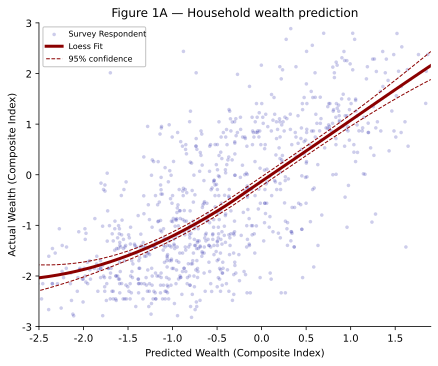

In [3]:
# 图 1A：沿用归档 fig1.R 的坐标方向和二阶 LOESS 设定。
# 先读入哈希后的电话调查特征表，再只检查本图必需的真实财富与保存预测两列。
# “哈希”意味着其他特征名称被遮蔽；这两列仍足够重画散点，但不足以重训弹性网。
phone = pd.read_csv(ARCHIVE / "modeling/data/train/PhoneSurveyFeatsHash.csv")
require_columns(phone, ["wealthActual", "wealthPredicted"], "PhoneSurveyFeatsHash")

# 只保留本图需要的两列并删除任一列缺失的记录。
# to_numpy 把 pandas 列转为数值数组，便于 NumPy 计算相关和 LOESS。
phone = phone[["wealthActual", "wealthPredicted"]].dropna()
actual_wealth = phone["wealthActual"].to_numpy()
predicted_wealth = phone["wealthPredicted"].to_numpy()

# Pearson r 衡量实际值与预测值的线性一致性；平方得到这里展示的 r²。
# 注意论文 Table S1 的 R² 应来自留出预测性能语境；此处按保存两列直接复算并明确标记。
fig1_r = float(np.corrcoef(actual_wealth, predicted_wealth)[0, 1])
fig1_r2 = fig1_r ** 2
print(f"保存预测 n={len(phone)}（正文约 856），Pearson r={fig1_r:.3f}，r²={fig1_r2:.3f}")

# 创建一张图和一个坐标轴。散点每个点代表一名电话调查受访者。
# 较低 alpha 让密集区域通过叠色显现；横轴/纵轴方向严格跟随归档 R 脚本。
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.scatter(
    predicted_wealth,  # 原 R 脚本横轴：Predicted
    actual_wealth,     # 原 R 脚本纵轴：Actual
    s=13,
    alpha=50 / 255,
    color=PAPER_COLORS["point_indigo"],
    edgecolor="none",
    label="Survey Respondent",
)

# 对应 R: newx <- seq(min(Predicted)-1, max(Predicted)+2, 0.1)
# 先生成平滑曲线的规则横坐标网格，再调用前面定义的局部二次回归函数。
# 两条虚线是拟合值上下 1.96 个近似标准误，只表示平滑均值的不确定性。
loess_x = np.arange(predicted_wealth.min() - 1, predicted_wealth.max() + 2.01, .1)
loess_fit, loess_se = loess_with_ci(predicted_wealth, actual_wealth, loess_x, span=1, degree=2)
ax.plot(loess_x, loess_fit, color=PAPER_COLORS["fit_red"], lw=3, label="Loess Fit")
ax.plot(loess_x, loess_fit - CONFIDENCE_Z * loess_se, color=PAPER_COLORS["fit_red"], lw=1, ls="--", label="95% confidence")
ax.plot(loess_x, loess_fit + CONFIDENCE_Z * loess_se, color=PAPER_COLORS["fit_red"], lw=1, ls="--")

# 固定坐标范围和英文轴标题，以便与论文面板直接对照。
# 最后统一排版并显示；此处没有保存图片，也没有改写任何数据文件。
ax.set(
    xlim=(-2.5, 1.9),
    ylim=(-3, 3),
    xlabel="Predicted Wealth (Composite Index)",
    ylabel="Actual Wealth (Composite Index)",
    title="Figure 1A — Household wealth prediction",
)
ax.legend(frameon=True, fontsize=8, loc="upper left", edgecolor="0.7")
finish_figure(fig)

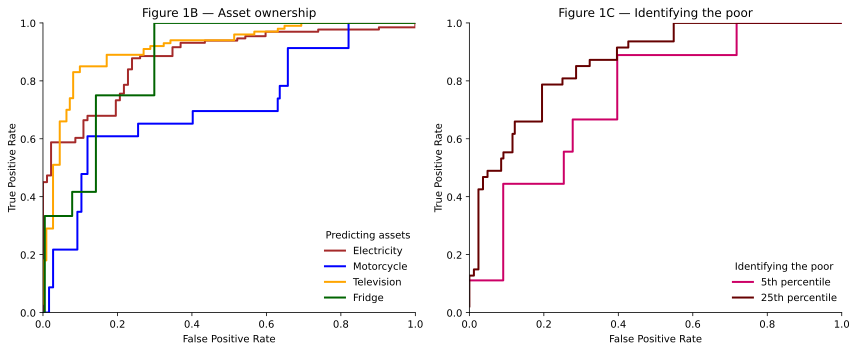

,资产,保存 ROC 的 AUC（本次积分）,ROC 点数
0,Electricity,0.878,123
1,Radio,0.410,119
2,Television,0.914,122
3,Refrigerator,0.870,120
4,Bicycle,0.663,124
5,Motorcycle,0.713,123
6,Poorest 5%,0.743,118
7,Poorest 25%,0.862,125


In [4]:
# 图 1B/C：ROC 文件两列依次为 false-positive rate 和 true-positive rate。
# 图 1B 严格只显示原论文的四项资产；全部六项仍用于表 S1 的 AUC 审计。
# 六项资产都进入 Table S1 审计，但正文 Figure 1B 只画其中四项。
# 字典把人类可读标签映射到归档文件名，防止在循环中写重复读取代码。
ALL_ASSET_ROC_FILES = {
    "Electricity": "own_electric_roc.csv",
    "Radio": "many_radio_roc.csv",
    "Television": "many_tv_roc.csv",
    "Refrigerator": "own_fridge_roc.csv",
    "Bicycle": "many_bike_roc.csv",
    "Motorcycle": "many_moto_roc.csv",
}
FIGURE_1_ASSETS = ["Electricity", "Motorcycle", "Television", "Refrigerator"]
POVERTY_ROC_FILES = {
    "Poorest 5%": ("poorest5_roc.csv", PAPER_COLORS["poor_5_magenta"]),
    "Poorest 25%": ("poorest25_roc.csv", PAPER_COLORS["poor_25_maroon"]),
}

# ROC 文件没有表头，第一列是假阳性率、第二列是真阳性率。
# 读取后删除缺失、按假阳性率排序，并断言所有概率都在 0–1 之间。
def load_roc(filename):
    """读取保存 ROC 点并验证两条坐标轴都在 0 到 1 范围内。"""
    roc = pd.read_csv(
        ARCHIVE / "modeling/data/train" / filename,
        header=None,
        names=["fpr", "tpr"],
    ).dropna().sort_values("fpr")
    assert roc["fpr"].between(0, 1).all() and roc["tpr"].between(0, 1).all()
    return roc

# np.trapezoid 用梯形法对离散 ROC 点积分，得到曲线下面积。
# 这里积分的是作者保存的曲线，不会重新训练分类器或选择阈值。
def saved_auc(roc):
    """仅对保存曲线积分；不重新训练分类器。"""
    return float(np.trapezoid(roc["tpr"].to_numpy(), roc["fpr"].to_numpy()))

# 一次性加载所有资产和贫困 ROC，后续画图与表格共用同一对象。
# 这样可确保 Figure 1 与 Table S1 的 AUC 来自完全相同的保存坐标。
asset_rocs = {label: load_roc(filename) for label, filename in ALL_ASSET_ROC_FILES.items()}
poverty_rocs = {
    label: (load_roc(filename), color)
    for label, (filename, color) in POVERTY_ROC_FILES.items()
}

# 所有可得到的曲线点都进入结果表，不能因为不在图 1B 中就丢失。
# 把每条曲线的标签、重算 AUC 和点数整理为长表，方便审计与论文值对照。
auc_rows = [
    {"资产": label, "保存 ROC 的 AUC（本次积分）": saved_auc(roc), "ROC 点数": len(roc)}
    for label, roc in asset_rocs.items()
]
auc_rows.extend(
    {"资产": label, "保存 ROC 的 AUC（本次积分）": saved_auc(roc), "ROC 点数": len(roc)}
    for label, (roc, _) in poverty_rocs.items()
)

# 建立左右两个面板：左侧资产拥有，右侧相对贫困。
# 循环只负责把已保存的 ROC 点连线；颜色沿用论文图例的大致对应关系。
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for label in FIGURE_1_ASSETS:
    roc = asset_rocs[label]
    axes[0].plot(
        roc["fpr"],
        roc["tpr"],
        lw=2,
        color=PAPER_ROC_COLORS[label],
        label=label if label != "Refrigerator" else "Fridge",
    )

for label, (roc, color) in poverty_rocs.items():
    axes[1].plot(roc["fpr"], roc["tpr"], lw=2, color=color, label=label.replace("Poorest ", "").replace("%", "th percentile"))

# 两轴都限制在 0–1。若需要判断随机基准，可想象从左下到右上的 45 度线。
# 曲线越靠左上，说明在较低假阳性率下能取得较高真阳性率。
axes[0].set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="Figure 1B — Asset ownership",
)
axes[0].legend(title="Predicting assets", frameon=False, loc="lower right")

axes[1].set(
    xlim=(0, 1),
    ylim=(0, 1),
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title="Figure 1C — Identifying the poor",
)
axes[1].legend(title="Identifying the poor", frameon=False, loc="lower right")

finish_figure(fig)
auc_rebuilt = pd.DataFrame(auc_rows)
display(auc_rebuilt.round({"保存 ROC 的 AUC（本次积分）": 3}))

### 4.2 Figure 2：全国高分辨率财富地图——为什么当前无法复刻

#### 原论文如何生成 Figure 2

原研究先把最优模型应用于约 150 万名用户，再依据夜间众数基站或位置重心把用户放到地图上。北部和西部按卢旺达 2,148 个行政 cell 汇总；南部展示由用户位置形成的更精细 Voronoi 分区；Kiyonza 附近约 1 平方公里的插图进一步显示每组 5–15 名用户的平均预测财富。小组化既提供更细空间分辨率，也避免直接展示单个用户位置。

#### 为什么客观行政边界仍不足以出图

区界只告诉我们多边形轮廓，不能产生任何财富值。要复刻 Figure 2，至少还需：每名全国用户的模型预测、能推断其夜间基站/重心的完整 CDR、基站 GPS 坐标，以及原研究的分组或空间连接结果。当前归档中的全国预测、原始 CDR 和塔址文件都只有表头或一行格式示例。

因此本节只用审计表打印缺失行数，不把 Figure 3 的 30 个地区均值放大冒充高分辨率结果，也不引入其他年份的塔址或现代贫困地图。**“无法复刻”在这里是由数据可用性支持的结论，而不是代码没有写完。**


In [5]:
# 依次从前面的审计表查找全国预测、原始 CDR 与塔址的真实数据行数。
# iloc[0] 取唯一匹配行；打印结果用于证明 Figure 2 缺少的不是地图边界，而是核心个体数据。
for label in ["全国预测（归档样例）","原始 CDR（归档样例）","塔址（归档样例）"]:
    r=audit_df.loc[audit_df.用途==label].iloc[0]
    print(f"{label}: {r['data rows']} 条数据行 → Figure 2 无法生成。")


全国预测（归档样例）: 1 条数据行 → Figure 2 无法生成。
原始 CDR（归档样例）: 1 条数据行 → Figure 2 无法生成。
塔址（归档样例）: 1 条数据行 → Figure 2 无法生成。


### 4.3 Figure 3：用独立 DHS 检验空间外推

#### 4.3.1 这一步为什么比训练样本内相关更重要？

Figure 1 仍然使用同一批电话调查对象和同一标签来源。Figure 3 则把模型应用于未接受电话调查的全国用户，再与由卢旺达国家统计机构独立收集的 2010 DHS 比较。模型训练时没有看到 DHS 结果，因此二者的空间相关不是把同一标签重复拟合出来的机械关系。

Figure 3A 是 2009 CDR 模型预测的 30 区平均财富，Figure 3B 是 2010 DHS 12,792 户按抽样权重计算的区平均财富。Figure 3C 比较两者；Figure 3D 比较地区用电率；Figure 3E 下沉到 DHS 聚类尺度。论文强调的区级财富相关约 0.916–0.917，用电相关约 0.93；聚类财富约 0.79。

#### 4.3.2 原论文的空间汇总逻辑

手机侧先把用户分配到夜间众数基站，在每个基站 Voronoi 单元内平均个体预测，再根据该 Voronoi 单元落入某行政区的面积比例加权。DHS 侧在行政区内按家庭抽样权重计算财富均值。散点大小与人口/家庭扩展权重相关，加权回归使大人口地区对拟合线贡献更大。

这不是把 DHS 与手机用户逐户匹配；两边的人不同，比较的是同一空间单元的统计量。强相关说明模型恢复了地区相对排序，但不能直接证明全国每个个体预测准确。地区层面还可能受城乡差异驱动，因此补充 Figure S6 会进一步观察城乡内部关系。

#### 4.3.3 本 Notebook 实际做什么

归档保留了已经完成空间匹配后的 `districts2010.csv` 和 `clusters2010.csv`。本 Notebook 可以重新计算加权 Pearson 相关、加权 OLS 和置信区间，并用客观 2012 区界重画地图；但不能从原始 DHS 家庭、基站和用户位置重新执行 Voronoi 叠加。因此这里属于**原始空间汇总中间结果重绘**。

两张地图分别按各自保存值的实际最小值和最大值映射到同一紫色系，并配独立色条。这样能看空间排序，但不应仅凭两图颜色深浅直接比较绝对数值，因为每幅图的色标范围不同。地图配色不影响 Figure 3C–E 的相关与加权回归。


In [6]:
# 读入保存验证输出，并定义按 DHS 家庭权重加权的 Pearson 相关。
# districts2010 每行是一个行政区，clusters2010 每行是一个 DHS 聚类汇总。
# 两表已经包含 CDR 与 DHS 的财富/用电汇总及家庭权重，因此从空间匹配后的阶段开始。
d2010 = pd.read_csv(ARCHIVE / "validation/data/out/districts2010.csv")
c2010 = pd.read_csv(ARCHIVE / "validation/data/out/clusters2010.csv")

# 先验证计算必需的五列，再核对行数。列名缺失通常表示拿错文件或归档版本变化。
# 487 与论文 492 的差异被明确写进断言和后文限制，不会被隐藏。
required_validation_columns = ["hhWeight", "dhsWealth", "cdrWealth", "dhsElec", "cdrElec"]
require_columns(d2010, required_validation_columns, "districts2010")
require_columns(c2010, required_validation_columns, "clusters2010")
assert len(d2010) == 30, "districts2010 的行数应为 30。"
assert len(c2010) == 487, "clusters2010 的行数应为 487。"

# 加权 Pearson 相关先删除缺失和非正权重，再计算加权均值、协方差与标准差乘积。
# 权重代表 DHS 家庭/人口扩展的重要性，使大人口空间单元对总体相关贡献更大。
def weighted_corr(x, y, weights):
    """计算加权 Pearson 相关；无效值和非正权重不会参与计算。"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    weights = np.asarray(weights, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(weights) & (weights > 0)
    x, y, weights = x[valid], y[valid], weights[valid]

    mean_x = np.average(x, weights=weights)
    mean_y = np.average(y, weights=weights)
    covariance = np.sum(weights * (x - mean_x) * (y - mean_y))
    scale = np.sqrt(np.sum(weights * (x - mean_x) ** 2) * np.sum(weights * (y - mean_y) ** 2))
    return float(covariance / scale)

# 加权 OLS 用一列常数和一列 x 构建设计矩阵，对应回归 y = 截距 + 斜率×x。
# 矩阵乘以权重后求系数；再用残差方差近似系数协方差和拟合均值标准误。
def weighted_ols_with_ci(x, y, weights, x_new):
    """拟合与 R lm(y ~ x, w=weights) 相同的加权 OLS；区间使用正态近似。"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    weights = np.asarray(weights, dtype=float)
    x_new = np.asarray(x_new, dtype=float)

    valid = np.isfinite(x) & np.isfinite(y) & np.isfinite(weights) & (weights > 0)
    x, y, weights = x[valid], y[valid], weights[valid]
    design = np.column_stack([np.ones_like(x), x])
    weighted_design = design * weights[:, None]
    information = design.T @ weighted_design
    coefficients = np.linalg.pinv(information) @ (weighted_design.T @ y)
    residuals = y - design @ coefficients

    residual_variance = np.sum(weights * residuals ** 2) / max(len(x) - 2, 1)
    covariance = residual_variance * np.linalg.pinv(information)
    prediction_design = np.column_stack([np.ones_like(x_new), x_new])
    fitted = prediction_design @ coefficients
    standard_error = np.sqrt(np.einsum("ij,jk,ik->i", prediction_design, covariance, prediction_design))
    return fitted, standard_error

# 论文 R 图用权重控制点大小。Matplotlib 的 s 表示面积，因此先得到相对半径再平方。
# clip 防止标准化后极小权重产生零或负半径；这只影响显示，不影响回归。
def r_style_point_area(weights, dot_size=1):
    """近似 R 脚本 scale(weights)+2 的相对点大小，同时适配 Matplotlib 的面积单位。"""
    weights = np.asarray(weights, dtype=float)
    z_scores = (weights - weights.mean()) / weights.std(ddof=0)
    radius = np.clip(z_scores + 2, .4, None) * dot_size
    return (5.5 * radius) ** 2

def padded_data_limits(values, padding=.04):
    """模拟 base R plot 的轻微留白：坐标轴由观测点而非外推置信线决定。"""
    values = np.asarray(values, dtype=float)
    lower = np.nanmin(values)
    upper = np.nanmax(values)
    margin = max((upper - lower) * padding, .05)
    return lower - margin, upper + margin

# 先打印三个核心加权相关，便于在画复杂多面板图之前快速核对数值。
print("地区财富加权 r:", round(weighted_corr(d2010["cdrWealth"], d2010["dhsWealth"], d2010["hhWeight"]), 3))
print("地区用电加权 r:", round(weighted_corr(d2010["cdrElec"], d2010["dhsElec"], d2010["hhWeight"]), 3))
print("聚类财富加权 r:", round(weighted_corr(c2010["cdrWealth"], c2010["dhsWealth"], c2010["hhWeight"]), 3))

# 读取客观边界并严格检查 30 个区名连接，防止无声错配。
# 两个来源的区名可能只在大小写、空格或连字符上不同，统一后才能安全连接。
# 这里只标准化拼写，不使用模糊匹配，避免把不同区错误合并。
def normalise_district_name(value):
    """去除空格和连字符后转小写，使两个来源的区名可以稳定匹配。"""
    return str(value).strip().lower().replace(" ", "").replace("-", "")

# 读取 shapefile 的字段和每个区的多边形坐标。District 字段提供与结果表连接的区名。
# shape.parts 允许一个行政区由多个不连续多边形片段组成。
reader = shapefile.Reader(str(BOUNDARY))
field_names = [field[0] for field in reader.fields[1:]]
district_field_index = field_names.index("District")

SHAPES = []
for record, shape in zip(reader.records(), reader.shapes()):
    points = np.asarray(shape.points)
    part_starts = list(shape.parts) + [len(points)]
    polygon_parts = [
        points[part_starts[index]:part_starts[index + 1]]
        for index in range(len(part_starts) - 1)
    ]
    SHAPES.append({
        "name": record[district_field_index],
        "key": normalise_district_name(record[district_field_index]),
        "parts": polygon_parts,
    })
assert len(SHAPES) == 30, "2012 区界应包含 30 个区。"

# draw_map 接收“区名 → 数值”的 Series，把每个区按指定色标着色。
# 先断言 30 个区都成功匹配，防止缺区被无声画成背景色。
def draw_map(ax, values, title, norm=PAPER_WEALTH_NORM, cmap=PAPER_WEALTH_CMAP):
    """按指定的颜色映射与数值尺度给以区名为索引的结果上色。"""
    lookup = {
        normalise_district_name(district): float(value)
        for district, value in values.items()
        if pd.notna(value)
    }
    missing = [shape["name"] for shape in SHAPES if shape["key"] not in lookup]
    assert not missing, f"边界与结果未匹配的区：{missing}"

    mapper = cm.ScalarMappable(norm=norm, cmap=cmap)
    for shape in SHAPES:
        fill_colour = mapper.to_rgba(lookup[shape["key"]])
        for polygon in shape["parts"]:
            ax.add_patch(
                patches.Polygon(
                    polygon,
                    closed=True,
                    facecolor=fill_colour,
                    edgecolor="white",
                    linewidth=.35,
                )
            )

    all_points = np.vstack([part for shape in SHAPES for part in shape["parts"]])
    ax.set(
        xlim=(all_points[:, 0].min(), all_points[:, 0].max()),
        ylim=(all_points[:, 1].min(), all_points[:, 1].max()),
        aspect="equal",
        title=title,
        facecolor="#0C0C12",
    )
    ax.set_axis_off()
    return mapper

地区财富加权 r: 0.916
地区用电加权 r: 0.926
聚类财富加权 r: 0.79


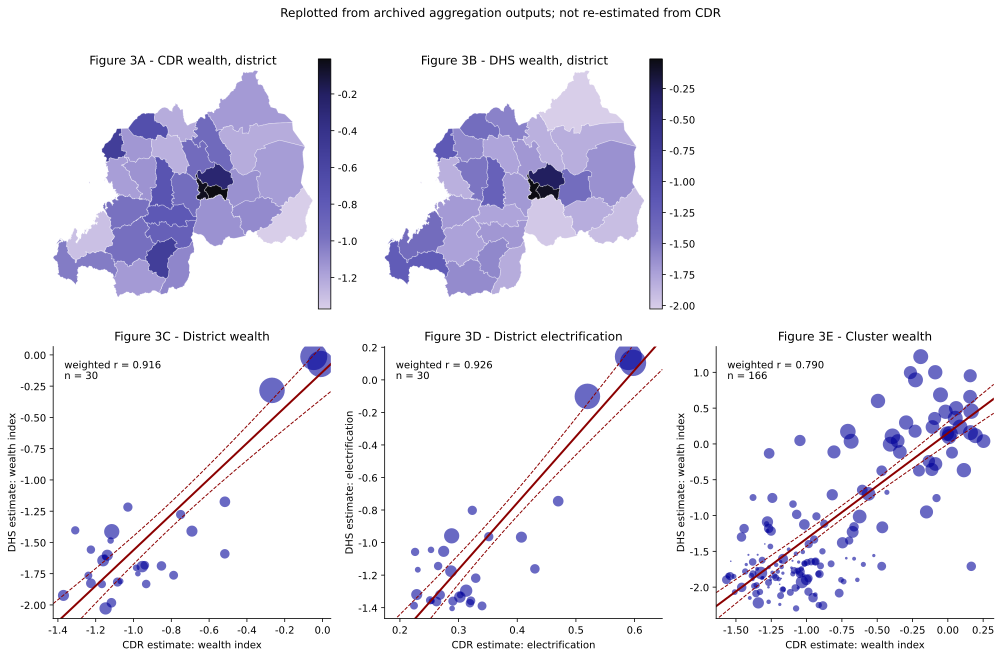

In [7]:
# 图 3A–E：保存汇总输出的地图与散点重绘。
# 创建 2×3 面板：上排两张地图加一个空位，下排对应 Figure 3C、3D、3E。
# 该单元仍输出 SVG；较高 dpi 只提高下方地图栅格层在 SVG 内的清晰度。
fig, axes = plt.subplots(2, 3, figsize=(14, 9), dpi=200)

# 两张地图分别按各自归档数值的实际范围着色；旁侧色条给出对应数值。
# 以 district 为索引取 CDR 财富；每幅地图单独用自身最小/最大值建立连续色标。
# 因此颜色用于看各自空间排序，不能跨两张地图直接把同一颜色当作同一绝对值。
cdr_map_values = d2010.set_index("district")["cdrWealth"]
cdr_mapper = draw_map(
    axes[0, 0],
    cdr_map_values,
    "Figure 3A - CDR wealth, district",
    norm=colors.Normalize(vmin=float(cdr_map_values.min()), vmax=float(cdr_map_values.max())),
    cmap=PAPER_WEALTH_CMAP,
)

dhs_map_values = d2010.set_index("district")["dhsWealth"]
dhs_mapper = draw_map(
    axes[0, 1],
    dhs_map_values,
    "Figure 3B - DHS wealth, district",
    norm=colors.Normalize(vmin=float(dhs_map_values.min()), vmax=float(dhs_map_values.max())),
    cmap=PAPER_WEALTH_CMAP,
)
# GitHub 对超大 SVG 中成千上万条地图路径兼容不稳定。这里只把两张地图的
# 多边形填色层嵌入为高分辨率图像；标题、色条和下排统计图仍保持矢量。
for map_axis in axes[0, :2]:
    for polygon_patch in map_axis.patches:
        polygon_patch.set_rasterized(True)

fig.colorbar(cdr_mapper, ax=axes[0, 0], fraction=.045, pad=.02)
fig.colorbar(dhs_mapper, ax=axes[0, 1], fraction=.045, pad=.02)
axes[0, 2].axis("off")

# 这个函数把三个散点面板的共同步骤集中起来：删缺失、算加权 r、拟合加权 OLS、画置信线。
# label 只控制轴标题，x/y 列决定比较财富还是用电，dot_size 控制视觉大小。
def plot_validation_scatter(ax, data, x_column, y_column, label, title, dot_size=1):
    """按归档 prettyPlot 的规则画加权 OLS、95% 置信区间和权重大小点。"""
    # R 的 lm 会自动省略缺失行；Python 这里显式做同样处理。
# 显式只保留 x、y 与权重三列，再模仿 R 的 lm 自动删除缺失行。
# 坐标范围由真实观测点决定，外推的置信线不会把图幅不必要地拉大。
    subset = data[[x_column, y_column, "hhWeight"]].dropna()
    correlation = weighted_corr(subset[x_column], subset[y_column], subset["hhWeight"])
    x_values = subset[x_column].to_numpy()
    y_values = subset[y_column].to_numpy()
    x_limits = padded_data_limits(x_values)
    y_limits = padded_data_limits(y_values)
    # 只在可见横轴范围内计算回归线，避免依赖 GitHub 可能移除的 SVG clip-path。
    x_grid = np.linspace(x_limits[0], x_limits[1], 200)
    fitted, standard_error = weighted_ols_with_ci(x_values, y_values, subset["hhWeight"], x_grid)

# 散点面积反映 DHS 权重；实线为加权回归，虚线为拟合均值的近似 95% 置信区间。
# 图内同时打印 weighted r 与有效样本数，避免读者只凭斜率判断拟合强度。
    ax.scatter(
        x_values,
        y_values,
        s=r_style_point_area(subset["hhWeight"], dot_size),
        alpha=150 / 255,
        color=PAPER_COLORS["point_indigo"],
        edgecolor="none",
    )
    # 先在数值层面把曲线限制在纵轴范围内；NaN 会把越界部分断开。
    # 因此即使 GitHub 丢弃 SVG clip-path，也不存在能够穿出子图的线段。
    def visible_curve(curve):
        curve = np.asarray(curve, dtype=float)
        visible = (curve >= y_limits[0]) & (curve <= y_limits[1])
        return np.where(visible, curve, np.nan)

    lower_confidence = fitted - CONFIDENCE_Z * standard_error
    upper_confidence = fitted + CONFIDENCE_Z * standard_error
    ax.plot(x_grid, visible_curve(fitted), color=PAPER_COLORS["fit_red"], lw=2, label="Weighted OLS")
    ax.plot(x_grid, visible_curve(lower_confidence), color=PAPER_COLORS["fit_red"], lw=1, ls="--", label="95% confidence")
    ax.plot(x_grid, visible_curve(upper_confidence), color=PAPER_COLORS["fit_red"], lw=1, ls="--")

    ax.set(title=title, xlabel=f"CDR estimate: {label}", ylabel=f"DHS estimate: {label}", xlim=x_limits, ylim=y_limits)
    ax.text(
        .04,
        .95,
        f"weighted r = {correlation:.3f}\nn = {len(subset)}",
        transform=ax.transAxes,
        va="top",
        bbox={"facecolor": "white", "alpha": .8, "edgecolor": "none"},
    )

# 依次生成地区财富、地区用电和聚类财富三个验证面板。
# suptitle 再次提醒：这些数值来自归档汇总输出，不是本 Notebook 重新估计的 CDR 模型。
plot_validation_scatter(axes[1, 0], d2010, "cdrWealth", "dhsWealth", "wealth index", "Figure 3C - District wealth")
plot_validation_scatter(axes[1, 1], d2010, "cdrElec", "dhsElec", "electrification", "Figure 3D - District electrification")
plot_validation_scatter(axes[1, 2], c2010, "cdrWealth", "dhsWealth", "wealth index", "Figure 3E - Cluster wealth", dot_size=.75)

fig.suptitle("Replotted from archived aggregation outputs; not re-estimated from CDR", y=1.01)
finish_figure(fig)

## 5. 补充材料：理解主结果背后的方法、稳健性与边界

### 5.1 Figure S1：DFA 特征构造的教学示意

#### 原补充图表达什么？

原 Figure S1 是一个正式的确定性有限自动机状态图：`q0` 为起始状态，`q3` 为接受状态；合法转移把 CDR 集合依次变为分组后的记录、字段集合、单个字段和最终数值。一次完整合法遍历产生一个行为特征。例如“工作时间内每周平均通话时长的周际标准差”需要依次完成：筛选工作时间 → 按本人分组 → 按周再分组 → 选择时长 → 每周求均值 → 跨周求标准差。

论文选择 DFA 而非逐一手工编写 5,088 个指标，意在用少量规则系统探索大特征空间，并减少研究者任意挑特征的自由度。代价是许多最终特征难以直观解释，而且高度相关，必须结合正则化筛选。

#### 本 Notebook 为什么只画简化流程？

公开归档没有完整原始 CDR，无法实际遍历 DFA 生成全部特征。下面代码把复杂状态机压缩成“原始事件 → 本人活动/网络/空间行为 → 5,088 维候选矩阵 → 弹性网结果”的教学流程。它帮助读者理解数据流向，但不是原 Figure S1 的逐节点视觉复刻，也不包含实证数值。


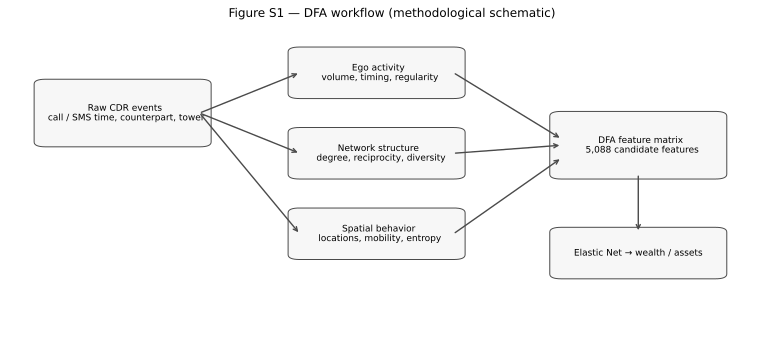

In [8]:
# 图 S1：方法流程图，不输入任何替代数据。
# 这一单元只画教学流程，不读取任何 CSV，也不产生新的统计结果。
# boxes 列表中每个元组依次给出框的 x、y、宽、高和文字；坐标均在 0–1 画布比例中。
# 第一轮循环画圆角框，第二轮循环按起点/终点画箭头，最后添加标题并显示。
# 英文框中文字沿用论文术语；本段中文注释解释其含义和复刻等级。
fig,ax=plt.subplots(figsize=(11,5)); ax.axis("off"); ax.set(xlim=(0,1),ylim=(0,1))
boxes=[(.05,.63,.20,.18,"Raw CDR events\ncall / SMS time, counterpart, tower"),(.38,.78,.20,.13,"Ego activity\nvolume, timing, regularity"),(.38,.53,.20,.13,"Network structure\ndegree, reciprocity, diversity"),(.38,.28,.20,.13,"Spatial behavior\nlocations, mobility, entropy"),(.72,.53,.20,.18,"DFA feature matrix\n5,088 candidate features"),(.72,.22,.20,.13,"Elastic Net → wealth / assets")]
for x,y,w,h,t in boxes: ax.add_patch(patches.FancyBboxPatch((x,y),w,h,boxstyle="round,pad=.015",facecolor="#F7F7F7",edgecolor="#4A4A4A")); ax.text(x+w/2,y+h/2,t,ha="center",va="center",fontsize=9)
for a,b in [((.25,.72),(.38,.845)),((.25,.72),(.38,.595)),((.25,.72),(.38,.345)),((.58,.845),(.72,.64)),((.58,.595),(.72,.62)),((.58,.345),(.72,.58)),((.82,.53),(.82,.35))]: ax.annotate("",xy=b,xytext=a,arrowprops={"arrowstyle":"->","color":"#4A4A4A","lw":1.4})
ax.set_title("Figure S1 — DFA workflow (methodological schematic)"); fig.tight_layout(); plt.show()


### 5.2 Figure S2：训练样本量如何限制模型表现

#### 要检验的不是“更多特征”，而是“更多有标签的人”

原研究有数十亿条通信事件和 5,088 个特征，但真正昂贵的是同时拥有问卷标签与 CDR 的独立受访者，只有 856 人。Figure S2 从完整样本中随机抽取更小的训练子集，重新训练并在留出数据上计算 R²，以回答：性能瓶颈是否主要来自标注样本太少？

保存文件第一列是留出比例。归档 R 脚本用 `856 × (1 − 留出比例)` 把它换算为训练人数，第二列是测试 R²。随着训练人数增加，LOESS 趋势仍在上升，并且到最大样本量附近没有明显平台，作者据此推断继续扩大电话调查很可能改善准确率。

测试 R² 可以为负：这表示在该次小样本情形下，模型比“对所有人都预测测试集均值”的基准还差，并不表示代码错误。Notebook 保留这类点，避免只展示有利结果。曲线只总结本实验范围内的经验趋势，不能保证样本增加到任意规模时仍按同样速度提升。


,held_out_fraction,test_r2,training_n_as_original_script
0,0.05,0.407182,813.20
1,0.10,0.429076,770.40
2,0.20,0.406685,684.80
3,0.30,0.392231,599.20
4,0.40,0.401820,513.60
5,0.50,0.382929,428.00
6,0.60,0.378998,342.40
7,0.70,0.341083,256.80
8,0.80,0.321203,171.20
9,0.90,0.179582,85.60


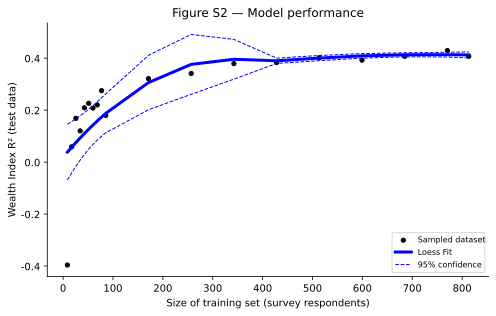

In [9]:
# 图 S2：按 figS2.R 的输入与二阶 LOESS 设定重画；置信区间为近似。
# 保存文件扩展名虽为 .cvs，但内容仍是逗号分隔表；文件没有表头，因此手工指定两列名称。
# 19 行断言确保没有把空行、错误分隔符或其他版本误读成实验结果。
sample_size = pd.read_csv(
    ARCHIVE / "modeling/data/train/sampleSize.cvs",
    header=None,
    names=["held_out_fraction", "test_r2"],
)
assert len(sample_size) == 19, "保存的样本量实验应有 19 行。"

# 第一列是留出比例，不是训练人数；按原脚本用 856×(1−比例) 换算。
# 先 display 原表与换算列，让读者能检查横轴不是凭空生成。
sample_size["training_n_as_original_script"] = 856 * (1 - sample_size["held_out_fraction"])
display(sample_size)

# LOESS 需要按横轴顺序连线，因此 argsort 只决定绘图顺序，不删除或改变任何实验点。
x_values = sample_size["training_n_as_original_script"].to_numpy()
y_values = sample_size["test_r2"].to_numpy()
order = np.argsort(x_values)
loess_fit, loess_se = loess_with_ci(x_values, y_values, x_values[order], span=1, degree=2)

# 黑点是保存的每个样本量实验结果，蓝线为局部趋势，虚线为近似置信带。
# 最后一个负 R² 被原样保留，用于展示极小训练集可能劣于均值基准。
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x_values, y_values, color="black", s=18, label="Sampled dataset")
ax.plot(x_values[order], loess_fit, color="blue", lw=3, label="Loess Fit")
ax.plot(x_values[order], loess_fit - CONFIDENCE_Z * loess_se, color="blue", lw=1, ls="--", label="95% confidence")
ax.plot(x_values[order], loess_fit + CONFIDENCE_Z * loess_se, color="blue", lw=1, ls="--")
ax.set(
    xlabel="Size of training set (survey respondents)",
    ylabel="Wealth Index R² (test data)",
    title="Figure S2 — Model performance",
)
ax.legend(frameon=True, loc="lower right", fontsize=8)
finish_figure(fig)

### 5.3 Figure S3：哪些手机特征单独与财富或摩托车相关？

#### Figure S3 的三个面板

- **Panel A**：对每个候选特征单独做五折交叉验证回归，画测试 R² 分布。大多数单特征预测力很弱，只有少数位于右尾。
- **Panel B**：列出与财富最强的代表性特征。前列多与一阶联系人（alter）的短信/通话时间熵有关，说明社交网络成员行为的规律性含有预测信息。
- **Panel C**：按本人/联系人、通话/短信、国际通信、移动、局部网络和全局网络等 11 类画分布，并与摩托车分类的 AUC 对照。财富较多受短信类特征预测，摩托车拥有与联系人移动模式更相关。

#### 应如何解释这些相关？

这些是**单变量、预测性关联**，不是最终 101 特征模型的系数，也不是因果机制。某类特征整体较高，不代表发送更多短信会使人变富；它可能同时反映识字、职业、城市居住、社交网络或资费承受能力。论文明确提醒，对事后可讲出故事的相关模式要保持谨慎。

#### 当前归档的限制

`feature_r2.csv` 只有 1,696 行，而论文描述的候选空间为 5,088 个特征，可能与归档保存层级、变换版本或筛选阶段有关；现有材料不足以确定差异来源。因此下面只对 1,696 行做诚实重绘，不把分布称为完整 5,088 特征结果。代码先展示前 20 项，再画概率直方图和按原脚本规则重建的 11 类小提琴图。


,Feature,保存的财富关联指标,featureLevel.0,featureLevel.1
860,CDR_over9secs_localNetwork-numCallsOut_SMS-nof...,0.375967,Alter,Communication
855,CDR_over9secs_localNetwork-numCallsOut_SMS-nof...,0.370994,Alter,Communication
874,CDR_over9secs_localNetwork-numCallsOut_SMS-not...,0.363529,Alter,Communication
888,CDR_over9secs_localNetwork-numCallsOut_SMS-wor...,0.356146,Alter,Communication
883,CDR_over9secs_localNetwork-numCallsOut_SMS-wor...,0.353631,Alter,Communication
869,CDR_over9secs_localNetwork-numCallsOut_SMS-not...,0.351145,Alter,Communication
858,CDR_over9secs_localNetwork-numCallsOut_SMS-nof...,0.338130,Alter,Communication
870,CDR_over9secs_localNetwork-numCallsOut_SMS-not...,0.330454,Alter,Communication
856,CDR_over9secs_localNetwork-numCallsOut_SMS-nof...,0.329534,Alter,Communication
873,CDR_over9secs_localNetwork-numCallsOut_SMS-not...,0.317756,Alter,Communication


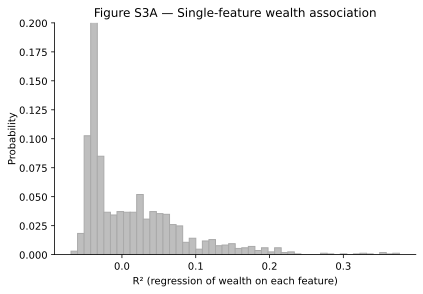

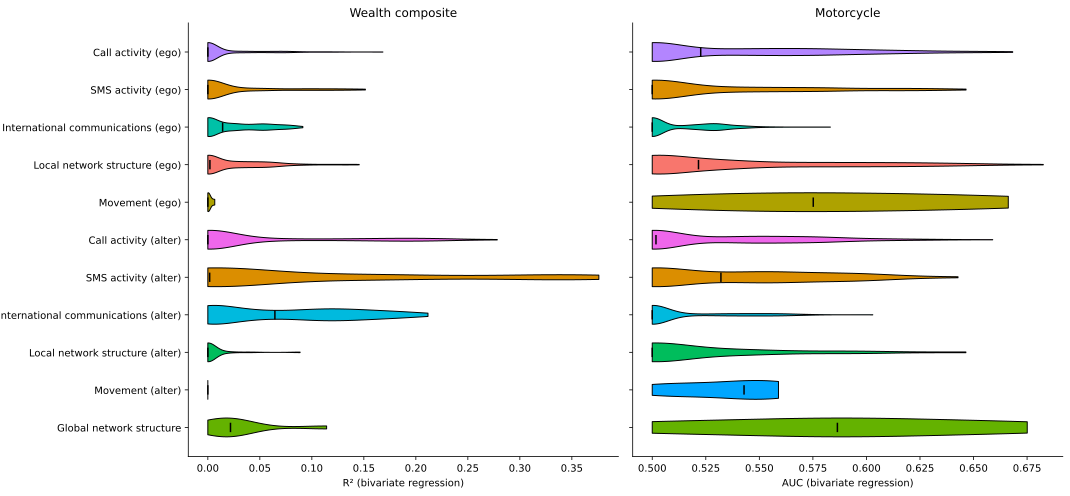

In [10]:
# 图 S3：按原 figS3.R 重画概率直方图、前 20 特征表和 11 类特征的小提琴图。
# 读取保存的单特征评估表，并检查特征名称、财富指标、摩托车指标和四层 DFA 分类字段。
# 1,696 行断言描述当前公开归档，而不是把它误写成论文完整 5,088 个候选特征。
feature_r2 = pd.read_csv(ARCHIVE / "modeling/data/train/feature_r2.csv")
require_columns(
    feature_r2,
    ["Feature", "wealthActual", "many_moto", "featureLevel.0", "featureLevel.1", "featureLevel.2", "featureLevel.3"],
    "feature_r2",
)
assert len(feature_r2) == 1696, "归档保留的单特征评估应为 1,696 行。"

# A/B：原脚本按财富关联值由大到小列出前 20 项，并将直方图标准化为概率。
# copy 避免后续添加分类列时修改最初读入对象的潜在视图。
# 先按财富关联指标降序展示前 20 个，帮助对照补充材料 Panel B。
feature_r2 = feature_r2.copy()
wealth_metric = feature_r2["wealthActual"].astype(float)
top_features = (
    feature_r2.sort_values("wealthActual", ascending=False)
    .loc[:, ["Feature", "wealthActual", "featureLevel.0", "featureLevel.1"]]
    .head(20)
)
display(top_features.rename(columns={"wealthActual": "保存的财富关联指标"}))

# 直方图权重统一为 1/有效特征数，因此纵轴是概率而非原始计数。
# 固定 50 个箱和 0–0.2 纵轴，便于接近原图的分布尺度。
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.hist(
    wealth_metric.dropna(),
    bins=50,
    weights=np.ones(wealth_metric.notna().sum()) / wealth_metric.notna().sum(),
    color=PAPER_COLORS["neutral_gray"],
    edgecolor="darkgrey",
)
ax.set(
    ylim=(0, .2),
    xlabel="R² (regression of wealth on each feature)",
    ylabel="Probability",
    title="Figure S3A — Single-feature wealth association",
)
finish_figure(fig)

# C：完全按照原脚本的 featureLevel 映射归为 11 类 DFA 特征。
# 原 R 脚本使用四层 featureLevel 字段组合 11 类；这里先复制为较短列名以便逐条映射。
# jp 是最终分类标签，初始为空；后面的布尔条件只给满足规则的行赋类名。
feature_r2["lev1"] = feature_r2["featureLevel.0"]
feature_r2["lev2"] = feature_r2["featureLevel.1"]
feature_r2["lev4"] = feature_r2["featureLevel.2"]
feature_r2["lev3"] = feature_r2["featureLevel.3"]
feature_r2["jp"] = ""

def set_group(mask, group):
    feature_r2.loc[mask, "jp"] = group

set_group((feature_r2.lev1 == "Ego") & (feature_r2.lev2 == "Communication") & (feature_r2.lev4 == "SMS"), "EgoSMS")
set_group((feature_r2.lev1 == "Alter") & (feature_r2.lev2 == "Communication") & (feature_r2.lev4 == "SMS"), "AlterSMS")
set_group((feature_r2.lev1 == "Ego") & (feature_r2.lev2 == "Communication") & (feature_r2.lev4.isin(["Domestic", "Ratio"])), "EgoCall")
set_group((feature_r2.lev1 == "Alter") & (feature_r2.lev2 == "Communication") & (feature_r2.lev4 == "Domestic"), "AlterCall")
set_group((feature_r2.lev1 == "Ego") & (feature_r2.lev2 == "Communication") & (feature_r2.lev4 == "International"), "EgoInternational")
set_group((feature_r2.lev1 == "Alter") & (feature_r2.lev2 == "Communication") & (feature_r2.lev4 == "International"), "AlterInternational")
set_group((feature_r2.lev1 == "Ego") & (feature_r2.lev2 == "Movement"), "EgoMovement")
set_group((feature_r2.lev1 == "Alter") & (feature_r2.lev2 == "Movement"), "AlterMovement")
set_group((feature_r2.lev1 == "Ego") & (feature_r2.lev2 == "Network"), "EgoNetwork")
set_group((feature_r2.lev1 == "Alter") & ((feature_r2.lev2 == "Network") | (feature_r2.lev3 == "distance")), "AlterNetwork")
set_group(feature_r2.lev4 == "TowerEntropy", "EgoMovement")
set_group(feature_r2.lev1 == "whole", "WholeGraph")

# 三个并行列表分别固定类别内部代码、图上标签和颜色；顺序必须一一对应。
# 同一种短信颜色在 ego/alter 中重复，是沿用归档脚本的视觉设定。
GROUPS = [
    "EgoCall", "EgoSMS", "EgoInternational", "EgoNetwork", "EgoMovement",
    "AlterCall", "AlterSMS", "AlterInternational", "AlterNetwork", "AlterMovement", "WholeGraph",
]
GROUP_LABELS = [
    "Call activity (ego)", "SMS activity (ego)", "International communications (ego)",
    "Local network structure (ego)", "Movement (ego)", "Call activity (alter)",
    "SMS activity (alter)", "International communications (alter)",
    "Local network structure (alter)", "Movement (alter)", "Global network structure",
]
GROUP_COLORS = [
    "#B385FF", "#DB8E00", "#00C1A7", "#F8766D", "#AEA200",
    "#EF67EB", "#DB8E00", "#00BADE", "#00BD5C", "#00A6FF", "#64B200",
]

# 小提琴宽度表示该类别指标的密度，黑线表示中位数。
# 财富 R² 下限截为 0、摩托车 AUC 下限截为 0.5，是复现原 R vPlot 的显示规则，不是改写源数据。
def plot_group_violins(ax, response, floor, title, x_label):
    """对应原 R vPlot：反向展示 11 个分类，空分类自动略过。"""
    prepared = feature_r2.copy()
    prepared[response] = prepared[response].clip(lower=floor)

    displayed = []
    for group, label, colour in zip(reversed(GROUPS), reversed(GROUP_LABELS), reversed(GROUP_COLORS)):
        values = prepared.loc[prepared["jp"] == group, response].dropna().to_numpy()
        if len(values):
            displayed.append((label, colour, values))

    violin = ax.violinplot(
        [values for _, _, values in displayed],
        positions=np.arange(1, len(displayed) + 1),
        orientation="horizontal",
        showmedians=True,
        showextrema=False,
    )
    for body, (_, colour, _) in zip(violin["bodies"], displayed):
        body.set_facecolor(colour)
        body.set_edgecolor("black")
        body.set_alpha(1)
    violin["cmedians"].set_color("black")
    ax.set_yticks(np.arange(1, len(displayed) + 1), [label for label, _, _ in displayed])
    ax.set(title=title, xlabel=x_label)

# 左右面板共享类别纵轴：左看财富单变量 R²，右看摩托车单变量 AUC。
# 这里比较的是分布而非最终多变量模型的重要性，不能把小提琴宽度解读为因果效应。
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
plot_group_violins(axes[0], "wealthActual", 0, "Wealth composite", "R² (bivariate regression)")
plot_group_violins(axes[1], "many_moto", .5, "Motorcycle", "AUC (bivariate regression)")
finish_figure(fig)

### 5.4 Figure S4、S5、S7：缺少关键输入时为什么必须停止

#### Figure S4：正则化、过拟合与 101 个特征

原 Figure S4A 沿正则化路径比较训练折和测试折 R²。强惩罚时进入模型的特征很少，训练/测试表现都低；逐渐减弱惩罚后，两者改善，在 101 个特征附近测试表现最优；继续减弱惩罚时训练表现仍升、测试表现下降，出现过拟合。Panel B 展示同一路径上各特征类别的构成如何从联系人短信类逐渐变得多样。

严格复刻需要完整受访者×5,088 特征矩阵、响应变量、抽样权重、每折划分和参数网格。归档 `trainFeats.csv` 只有一行，无法与数百行 `trainObj.csv` 配对，也不可能恢复每个 λ 下的系数路径。因此不能只凭论文图形手工描出一条看似合理的曲线。

#### Figure S5：两套 Voronoi 如何把手机与 DHS 放到同一空间单位

原图叠加约 300 个手机基站及其 Voronoi 单元、492 个 DHS 聚类中心及其 Voronoi 单元。对每个 DHS 聚类，计算它与各基站单元的面积交叠比例，再用这些比例加权基站单元的平均 CDR 财富。图中插图的数字正是面积权重。严格复刻需要真实塔址、DHS 聚类坐标和边界几何；当前归档只保留示例/遮蔽位置。

#### Figure S7：夜间灯光与家庭用电不是同一个概念

原研究使用 2012 年 4 月版 VIIRS-DNB 平均辐亮度，分辨率约 0.742×0.742 公里。卫星夜光反映城市灯光、道路、火点等外部辐亮度；手机模型预测的是问卷“家庭是否有电”。Kigali 内二者应相关，但农村家庭即使通电也可能没有足够亮度被卫星捕捉。严格复刻需要当年精确栅格和 150 万用户的空间化用电预测，归档均不完整。依照任务要求，本 Notebook 不用现代 VIIRS、其他年份手机数据或替代电气化栅格。

下面代码只打印实际行数，作为停止的可审计证据；不生成伪造的 S4、S5 或 S7。


In [11]:
# 先直接读取 S4 特征与响应文件并打印形状：完整训练要求两者行数可配对。
# 随后从统一审计表读取 S5/S7 所需塔址、DHS 与 CDR 行数。
# 这一单元没有 try/except 隐藏错误，也没有用随机数补齐缺失矩阵。
s4x=pd.read_csv(ARCHIVE/"analysis/figS4/data/in/trainFeats.csv"); s4y=pd.read_csv(ARCHIVE/"analysis/figS4/data/in/trainObj.csv",header=None)
print(f"S4 trainFeats: {s4x.shape[0]} 行 × {s4x.shape[1]} 列；trainObj: {s4y.shape[0]} 行。")
for label in ["塔址（归档样例）","DHS 2010 住户数据（归档样例）","原始 CDR（归档样例）"]:
    r=audit_df.loc[audit_df.用途==label].iloc[0]; print(f"{label}: {r['data rows']} 行，{r['判断']}。")
print("结论：S4、S5、S7 不使用模拟或替代数据，因此不出图。")


S4 trainFeats: 1 行 × 5088 列；trainObj: 865 行。
塔址（归档样例）: 1 行，样例/不足，不能重跑。
DHS 2010 住户数据（归档样例）: 1 行，样例/不足，不能重跑。
原始 CDR（归档样例）: 1 行，样例/不足，不能重跑。
结论：S4、S5、S7 不使用模拟或替代数据，因此不出图。


### 5.5 Figure S6：城乡内部是否仍有相关？

全国地区财富相关可能主要由“Kigali 富、农村穷”这一明显城乡差异推动。如果只是这样，模型未必能识别同类地区内部更细的差别。Figure S6 因而把 2010 DHS 聚类分为 Kigali 城市区域与其他农村区域，分别比较 CDR 财富和 DHS 财富。

本 Notebook 按归档脚本逻辑，把 Gasabo、Kicukiro、Nyarugenge 三个 Kigali 区标记为 Urban，其余为 Rural；对每组重新计算按 `hhWeight` 加权的 Pearson 相关和加权 OLS。论文报告城市约 `r = 0.64`、农村约 `r = 0.50`：都低于合并样本约 0.79，但仍为正，说明结果不完全由城乡均值差异产生。

解释时仍需谨慎。聚类坐标被 DHS 随机扰动，且调查抽样本来就不是为聚类级代表性设计；拆分后样本更少、测量误差影响更大。因此 Figure S6 是稳健性证据，不应被当作精确的村级财富测量认证。


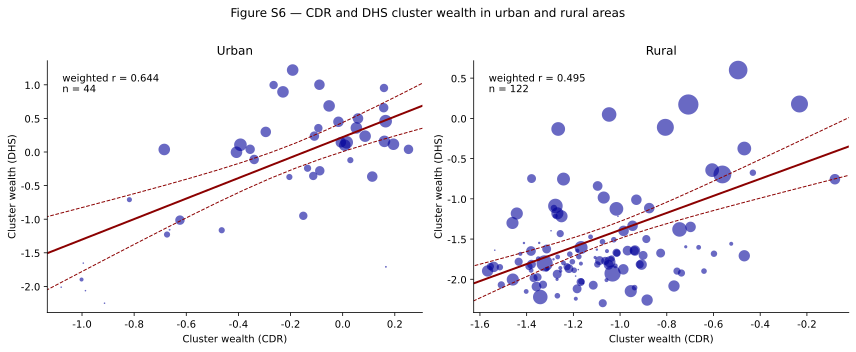

In [12]:
# 图 S6：沿用补充图的 Urban/Rural 分组与加权 OLS、95% 置信区间。
# 按补充材料/归档逻辑把 Kigali 的三个行政区作为城市组，其余聚类作为农村组。
# area_subsets 保存组名与数据副本，确保两个面板执行完全相同的统计流程。
KIGALI_DISTRICTS = {"Gasabo", "Kicukiro", "Nyarugenge"}
area_subsets = [
    ("Urban", c2010.loc[c2010["district"].isin(KIGALI_DISTRICTS)].copy()),
    ("Rural", c2010.loc[~c2010["district"].isin(KIGALI_DISTRICTS)].copy()),
]

# 创建并列城乡面板。每组先删除财富或权重缺失的聚类，再计算加权相关。
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=False, sharey=False)
for ax, (area, subset) in zip(axes, area_subsets):
    subset = subset.dropna(subset=["cdrWealth", "dhsWealth", "hhWeight"])
    correlation = weighted_corr(subset["cdrWealth"], subset["dhsWealth"], subset["hhWeight"])
    x_values = subset["cdrWealth"].to_numpy()
    y_values = subset["dhsWealth"].to_numpy()
    x_limits = padded_data_limits(x_values)
    y_limits = padded_data_limits(y_values)
    x_grid = np.arange(x_values.min() - 1, x_values.max() + 1.01, .1)
    fitted, standard_error = weighted_ols_with_ci(x_values, y_values, subset["hhWeight"], x_grid)

# 点大小仍按 DHS 权重，实线/虚线仍是加权 OLS 与近似 95% 置信区间。
# 各面板使用自身数据范围，便于观察组内关系；不要用视觉斜率直接比较两组方差。
    ax.scatter(
        x_values,
        y_values,
        s=r_style_point_area(subset["hhWeight"], dot_size=.75),
        alpha=150 / 255,
        color=PAPER_COLORS["point_indigo"],
        edgecolor="none",
    )
    ax.plot(x_grid, fitted, color=PAPER_COLORS["fit_red"], lw=2)
    ax.plot(x_grid, fitted - CONFIDENCE_Z * standard_error, color=PAPER_COLORS["fit_red"], lw=1, ls="--")
    ax.plot(x_grid, fitted + CONFIDENCE_Z * standard_error, color=PAPER_COLORS["fit_red"], lw=1, ls="--")
    ax.set(title=area, xlabel="Cluster wealth (CDR)", ylabel="Cluster wealth (DHS)", xlim=x_limits, ylim=y_limits)
    ax.text(
        .04,
        .95,
        f"weighted r = {correlation:.3f}\nn = {len(subset)}",
        transform=ax.transAxes,
        va="top",
        bbox={"facecolor": "white", "alpha": .85, "edgecolor": "none"},
    )

fig.suptitle("Figure S6 — CDR and DHS cluster wealth in urban and rural areas", y=1.01)
finish_figure(fig)

### 5.6 Figure S8：手机估计能否插补两轮传统调查之间的变化？

#### 政策思想实验

假设决策者在 2010 年需要识别较贫困地区，但新的 2010 DHS 尚未发布，通常只能使用 2007 DHS。论文问：2009 年手机记录产生的地区财富估计，是否比三年前的官方调查更接近随后公布的 2010 DHS？

Figure S8 为每个区连接三个点：2007 DHS、2009 CDR 插补、2010 DHS。由于三个来源的财富指数位置和尺度不同，原脚本把 2007 DHS 与 2009 CDR 分别标准化后映射到 2010 DHS 的均值和样本标准差，再比较相对地区变化。这个缩放只对齐尺度，不会让地区排序自动变得更相似。

论文报告 2009 CDR 与 2010 DHS 的地区相关约 0.91，高于 2007 与 2010 DHS 的约 0.84；若把 2010 年低于平均财富的 20 个区作为目标，2007 DHS 找对 14 个（70%），2009 CDR 找对 17 个（85%）。这支持“临时统计”的用途，但不是实时因果监测：模型若跨时间漂移，仍需新调查重新校准。

归档把 2009 CDR 地区值保存在 `districts2010.csv` 的 `cdrWealth` 列中。下面按原脚本缩放并排序，每第五个区高亮，其余以半透明灰线呈现。图的重点是单个地区在三时点的相对轨迹，而非线条之间的交叉本身。


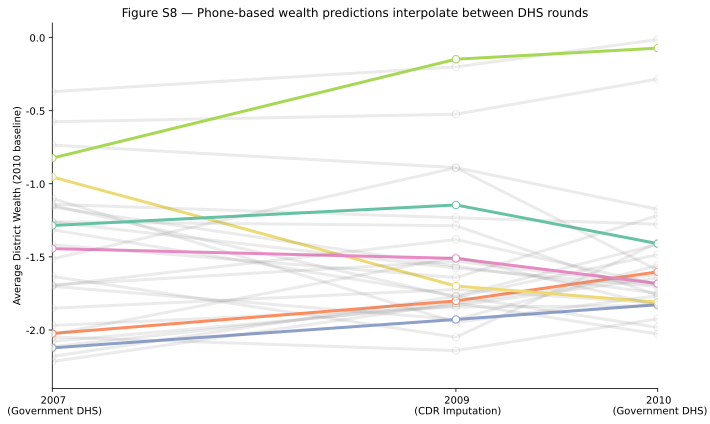

In [13]:
# 图 S8：严格按 figS8.R 比较 2007 DHS、2009 CDR 插补和 2010 DHS。
# 归档的 districts2010.cdrWealth 是脚本中使用的 2009 CDR 中间点，而不是 2010 的第三种真值。
# 读取 2007 地区汇总，并与已在 Figure 3 使用的 2010 文件按区名内连接。
# 内连接后仍须恰好 30 行，保证没有区名错拼、重复或丢失。
d2007 = pd.read_csv(ARCHIVE / "validation/data/out/districts2007.csv")
assert len(d2007) == 30, "districts2007 的行数应为 30。"

timeline = (
    d2007[["district", "dhsWealth"]]
    .rename(columns={"dhsWealth": "dhs2007"})
    .merge(
        d2010[["district", "cdrWealth", "dhsWealth", "hhWeight"]],
        on="district",
        how="inner",
    )
    .rename(columns={"cdrWealth": "cdr2009", "dhsWealth": "dhs2010", "hhWeight": "dhs_population_2010"})
)
assert len(timeline) == 30, "两个年份的区级文件应能按 district 完整匹配。"

# 原 R 脚本将 2007 DHS 和 2009 CDR 都缩放到 2010 DHS 的均值、标准差。
# 缩放先减去各自均值并除以各自样本标准差，再乘 2010 DHS 标准差并加 2010 均值。
# 它统一纵轴位置/尺度，但保留每个来源内部的 z 分数与地区排序。
def on_2010_dhs_scale(values):
    return (
        (values - values.mean()) / values.std(ddof=1)
        * timeline["dhs2010"].std(ddof=1)
        + timeline["dhs2010"].mean()
    )

# 分别缩放 2007 DHS 与 2009 CDR；2010 DHS 作为目标基线不变。
# 随后按原始 2009 CDR 值排序，只用于决定每第五个高亮区和图例顺序。
timeline["dhs2007_scaled"] = on_2010_dhs_scale(timeline["dhs2007"])
timeline["cdr2009_scaled"] = on_2010_dhs_scale(timeline["cdr2009"])
timeline = timeline.sort_values("cdr2009").reset_index(drop=True)

# 原图每五个区高亮一个；其余区使用透明灰色。
# 六种颜色对应 30 个区中每第五个区；其余区用低透明灰色保留整体背景。
# 高亮规则是展示选择，不参与任何相关、分类或缩放计算。
HIGHLIGHT_COLORS = ["#8DA0CB", "#FC8D62", "#EDDA74", "#E78AC3", "#66C2A5", "#A6D854"]
timeline["highlight"] = ((np.arange(len(timeline)) + 1) % 5 == 0)
timeline["colour"] = np.where(timeline["highlight"], "", "#808080")
timeline.loc[timeline["highlight"], "colour"] = [
    HIGHLIGHT_COLORS[index % len(HIGHLIGHT_COLORS)]
    for index in range(timeline["highlight"].sum())
]

# 每一行地区数据画一条 2007→2009→2010 折线，并在三个年份加空心点。
# 透明度只区分是否高亮；所有 30 个区都保留在图中。
fig, ax = plt.subplots(figsize=(10, 6))
years = np.array([2007, 2009, 2010])
for _, row in timeline.iterrows():
    values = [row["dhs2007_scaled"], row["cdr2009_scaled"], row["dhs2010"]]
    colour = row["colour"]
    alpha = 1 if row["highlight"] else 40 / 255

    ax.plot(years, values, color=colour, alpha=alpha, lw=3)
    ax.scatter(
        years,
        values,
        s=55,
        facecolor="white",
        edgecolor=colour,
        alpha=alpha,
        zorder=3,
    )

ax.set(
    xlim=(2007, 2010),
    ylim=(-2.4, .1),
    xticks=[2007, 2009, 2010],
    xticklabels=["2007\n(Government DHS)", "2009\n(CDR Imputation)", "2010\n(Government DHS)"],
    ylabel="Average District Wealth (2010 baseline)",
    title="Figure S8 — Phone-based wealth predictions interpolate between DHS rounds",
)
finish_figure(fig)

## 6. Table S1：如何阅读模型性能表，以及哪些列能够验证

Table 1 只是电话调查、CDR 与两轮 DHS 的描述性样本概况，按本次任务要求不复刻。Table S1 才是模型结果表，分为两个面板。

### 6.1 Panel A：连续财富模型比较

Panel A 用相关系数 `r` 和决定系数 `R²` 比较四种方案：最优 DFA 弹性网、最优 DFA 随机森林、五个直观特征模型和单个最佳 DFA 特征模型。`r` 侧重预测与真实值的线性排序一致性；`R²` 反映相对于预测均值基准解释了多少测试集变异。最优弹性网报告 `r=0.68, R²=0.46`，明显优于五个直观特征，说明系统化特征工程的增益大于单纯更换学习算法。

当前归档只保留最优财富模型的 `wealthActual/wealthPredicted`，所以只有这一行能重新计算。其他模型若只有论文最终数字而没有逐人留出预测，就不能验证其相关与 R²；下面把这些单元格留空，并明确标为“预测未保留”。

### 6.2 Panel B：二元资产分类

Panel B 报告 Accuracy、AUC、F score 和 Baseline。Accuracy 是总体预测正确比例，但在资产极不平衡时可能误导；例如几乎所有人都有收音机，全部预测“有”也能得到很高准确率。AUC 衡量排序能力，F score 平衡精确率与召回率，Baseline 是样本中阳性比例。

归档提供 ROC 坐标，因此 AUC 可以重新积分；但哈希数据没有可解释的逐户资产真实标签和每个阈值下的最终分类，无法重新计算 Accuracy、F1 或 Baseline。保存 ROC 数值积分与论文四舍五入值存在轻微差异时，应优先报告差异而不是调整曲线点。

> **读表原则**：论文报告值用于对照，不等于本 Notebook 已从原始 CDR 重训得到。只有“本次可复算”列才是当前公开文件能够独立验证的结果。


In [14]:
# 表 S1 Panel A：只复算保存的最佳 DFA 弹性网预测；其余模型预测没有保留。
# 手工构建四行模型对照表：只有第一行的 r/r² 能由保存的逐人财富预测重新计算。
# 其余论文值用于教学对照，本次可复算列明确设为 NaN，而不是复制论文数字冒充计算结果。
panel_a = pd.DataFrame([
    {
        "模型/输入": "Optimal DFA-based Elastic Net",
        "本次可复算 r": fig1_r,
        "本次可复算 r²": fig1_r2,
        "论文表 S1 r": .68,
        "论文表 S1 R²": .46,
        "证据": "保存 wealthActual/wealthPredicted",
    },
    {
        "模型/输入": "Intuitive 5-feature Elastic Net",
        "本次可复算 r": np.nan,
        "本次可复算 r²": np.nan,
        "论文表 S1 r": .44,
        "论文表 S1 R²": .20,
        "证据": "预测未保留，不能验证",
    },
    {
        "模型/输入": "Single-feature Elastic Net",
        "本次可复算 r": np.nan,
        "本次可复算 r²": np.nan,
        "论文表 S1 r": .61,
        "论文表 S1 R²": .38,
        "证据": "预测未保留，不能验证",
    },
    {
        "模型/输入": "Optimal DFA-based Random Forest",
        "本次可复算 r": np.nan,
        "本次可复算 r²": np.nan,
        "论文表 S1 r": .63,
        "论文表 S1 R²": .40,
        "证据": "预测未保留，不能验证",
    },
])
display(panel_a.round({"本次可复算 r": 3, "本次可复算 r²": 3, "论文表 S1 r": 2, "论文表 S1 R²": 2}))

# Panel B：AUC 可由保存曲线积分；其余三列需要被遮蔽的逐户二元标签。
# published_auc 收录补充 Table S1 与 Figure 1C 的论文 AUC 四舍五入值。
# 与前面从 ROC 点积分得到的 auc_rebuilt 合并后，差异列可显示离散积分/版本差别。
published_auc = {
    "Refrigerator": .88,
    "Electricity": .85,
    "Television": .84,
    "Bicycle": .68,
    "Motorcycle": .67,
    "Radio": .50,
    "Poorest 5%": .72,
    "Poorest 25%": .81,
}
# copy 保留最初重算 AUC 表；map 按资产标签匹配论文值。
# Accuracy、F1 与 baseline 没有逐人真实标签，整列用文字解释缺口而不填造数值。
panel_b = auc_rebuilt.copy()
panel_b["论文表 S1 AUC"] = panel_b["资产"].map(published_auc)
panel_b["差异（重算−论文）"] = panel_b["保存 ROC 的 AUC（本次积分）"] - panel_b["论文表 S1 AUC"]
panel_b["无法验证的表 S1 列"] = "Accuracy / F1 / baseline（需未掩码逐户标签）"
display(panel_b.round({"保存 ROC 的 AUC（本次积分）": 3, "论文表 S1 AUC": 2, "差异（重算−论文）": 3}))

,模型/输入,本次可复算 r,本次可复算 r²,论文表 S1 r,论文表 S1 R²,证据
0,Optimal DFA-based Elastic Net,0.714,0.51,0.68,0.46,保存 wealthActual/wealthPredicted
1,Intuitive 5-feature Elastic Net,NaN,NaN,0.44,0.20,预测未保留，不能验证
2,Single-feature Elastic Net,NaN,NaN,0.61,0.38,预测未保留，不能验证
3,Optimal DFA-based Random Forest,NaN,NaN,0.63,0.40,预测未保留，不能验证


,资产,保存 ROC 的 AUC（本次积分）,ROC 点数,论文表 S1 AUC,差异（重算−论文）,无法验证的表 S1 列
0,Electricity,0.878,123,0.85,0.028,Accuracy / F1 / baseline（需未掩码逐户标签）
1,Radio,0.410,119,0.50,-0.090,Accuracy / F1 / baseline（需未掩码逐户标签）
2,Television,0.914,122,0.84,0.074,Accuracy / F1 / baseline（需未掩码逐户标签）
3,Refrigerator,0.870,120,0.88,-0.010,Accuracy / F1 / baseline（需未掩码逐户标签）
4,Bicycle,0.663,124,0.68,-0.017,Accuracy / F1 / baseline（需未掩码逐户标签）
5,Motorcycle,0.713,123,0.67,0.043,Accuracy / F1 / baseline（需未掩码逐户标签）
6,Poorest 5%,0.743,118,0.72,0.023,Accuracy / F1 / baseline（需未掩码逐户标签）
7,Poorest 25%,0.862,125,0.81,0.052,Accuracy / F1 / baseline（需未掩码逐户标签）


## 7. 总结：论文发现、复刻发现与正确使用方式

### 7.1 论文的主要发现

1. **个体数字足迹具有可观预测力**：系统生成的 CDR 行为特征结合弹性网，可在留出受访者中预测连续财富和若干资产回答；最优模型显著优于五个直观特征基准。
2. **个体预测可以汇总为有意义的空间统计**：约 150 万用户的预测在 30 个区汇总后，与独立 2010 DHS 财富和用电率高度相关；聚类与城乡内部仍保留较弱但为正的关系。
3. **数字记录可能补充低频官方调查**：2009 手机估计对 2010 地区财富的拟合优于 2007 DHS，为两轮住户调查之间的低成本临时统计提供概念验证。
4. **这是一种预测框架而非因果模型**：研究没有识别手机行为对财富的因果效应，也没有证明模型能无校准地跨国家、运营商或时期迁移。

### 7.2 本 Notebook 实际完成了什么？

运行各图单元后，Figure 1A、1B–C、3、S2、S3、S6、S8 会依据 ICPSR 保存的原研究中间结果重新计算或重绘；Figure S1 是方法教学示意；Table S1 的财富相关和 AUC 可验证部分会重新计算。Figure 2、S4、S5、S7 不出图是经过文件行数与所需变量核对后的科研诚信结论，而不是执行遗漏。

### 7.3 复刻中发现的版本差异与技术限制

1. 哈希调查表有 857 条可用预测，而正文描述 856 名受访者；保存值给出的 Figure 1A 相关约 0.714，高于论文约 0.68。现有材料不足以确定是版本、过滤规则还是保存方式造成，故不擅自删行。
2. Figure 1A 与 S2 使用自实现二阶 LOESS（`span=1`）；点态置信带采用正态近似，不声称与 R `predict.loess` 的标准误逐点一致。
3. Figure 3、S6、S8 从保存的空间汇总结果开始，不是重新训练 CDR 模型，也没有重新执行用户定位或 Voronoi 面积叠加。
4. 2010 聚类输出实际 487 行，而论文为 492 个 DHS 聚类；聚类坐标随机扰动和缺失记录会影响细尺度比较，但归档没有足够信息恢复缺少的五个聚类。
5. Figure S3 只保存 1,696 个单特征结果，少于论文 5,088 个候选特征；不能据此恢复完整特征空间。
6. 世界银行 2012 区界只用于轮廓。区界年份、配色和投影可能与论文原图不同，不改变散点所用数值，但地图不应被称为逐像素复刻。

### 7.4 如何从头复跑本 Notebook

1. 在项目根目录打开本文件，确认同级存在 `ICPSR_100144-V5.1` 与 `external_data/rwa_district`。
2. 选择已安装 NumPy、pandas、Matplotlib、pyshp 和 Jupyter inline backend 的 Python/Anaconda 内核。
3. 从上到下选择 Run All。前置单元会设置路径和函数；数据审计断言会在文件缺失或行数异常时主动停止。
4. 阅读每幅图上方的 Markdown，再对照代码中的中文 `#` 注释和输出。不要只看图形而忽略复刻等级。
5. Notebook 不联网、不修改 ICPSR 原始文件，也不会把生成图写回原始数据目录。

### 7.5 若未来获得受限原数据，下一步应如何升级？

只有在依法获得原始 CDR、完整电话调查标签与权重、全国用户预测/位置、塔址、DHS 微观/GPS 和精确 VIIRS 版本后，才能：重新生成 5,088 个 DFA 特征；重做加权五折参数选择；复现 101 特征正则化路径；生成全国 Figure 2；重新完成基站—行政区—DHS 聚类的 Voronoi 叠加；以及从头复刻 S4、S5、S7。升级时还应记录随机种子、软件版本、每折样本 ID 和数据许可条件。

### 7.6 伦理与政策解释

用通信元数据推断贫困可能帮助资源配置，也可能造成监控、误分类和排除。最贫困者反而更可能没有手机或不活跃；若把模型直接用于福利资格，预测误差会产生真实伤害。任何实际应用都应进行代表性审计、误差与公平性评估、数据最小化、访问控制、知情治理、人工复核和定期重新校准。论文的技术可行性不能替代这些制度条件。


## 8. 参考文献、数据出处与章节对应

### 8.1 本次复刻直接依据的研究材料

1. Blumenstock, J., Cadamuro, G., & On, R. (2015). *Predicting poverty and wealth from mobile phone metadata*. **Science, 350**(6264), 1073–1076. https://doi.org/10.1126/science.aac4420
2. Blumenstock, J., Cadamuro, G., & On, R. (2015). *Supplementary Materials for Predicting poverty and wealth from mobile phone metadata*. Science. https://doi.org/10.1126/science.aac4420
3. Blumenstock, J., Cadamuro, G., & On, R. *Predicting Poverty and Wealth from Mobile Phone Metadata* (ICPSR 100144, Version 5). ICPSR. https://doi.org/10.3886/E100144V5

本 Notebook 只使用本地 `ICPSR_100144-V5.1` 中实际可读的文件。归档 README 对 CDR、DHS、塔址和全国预测的删减/遮蔽说明，是 Figure 2、S4、S5、S7 不可严格复刻的直接依据。

### 8.2 客观地图底图

4. World Bank. *Rwanda Admin Boundaries and Villages*（2012 年区界，CC BY 4.0）。https://datacatalog.worldbank.org/search/dataset/0041453/rwanda-admin-boundaries-and-villages

下载日期：2026-10-30。该文件只提供行政区几何形状；Figure 3 地图中的财富/用电数值全部来自 ICPSR 归档。

### 8.3 关键方法在原文中的位置

- 电话调查、CDR、DHS、财富 PCA 与 VIIRS：补充材料 Section I。
- DFA 规则、五个直观特征、单个最佳特征与 11 类特征：补充材料 Section II。
- 弹性网、五折交叉验证、样本量与模型解释：补充材料 Section III。
- 夜间众数基站、位置重心、Voronoi 面积权重、聚类与夜间灯光验证：补充材料 Section IV。
- 手机用户到全体人口的外部有效性及跨情境限制：补充材料 Section V。
- 临时统计、个体定向和动态监测的应用与风险：补充材料 Section VI。

### 8.4 Notebook 呈现格式参考

5. binbo233. *American Election Prediction 2020 MRP* Notebook. https://github.com/binbo233/American-Election-Prediction-2020-MRP

这里只参考“研究问题与验收标准前置、编号章节、Markdown 解释紧接代码、SVG 图表”的教学式组织方式；未使用其中任何数据、模型、结论或研究内容。
